<div style="background:#1F3F66;color:white;padding:28px 32px;border-radius:10px;border-bottom:6px solid #F2A541">
  <p style="margin:0;font-size:0.85em;letter-spacing:2px;text-transform:uppercase;opacity:0.8">Hackathon Data Science &amp; Risque · Université de Bordeaux</p>
  <h1 style="color:white;margin:8px 0 6px 0;font-size:2.2em">Réseaux bancaires et contagion</h1>
  <p style="margin:0;font-size:1.15em;color:#F2C27B">Simuler une crise · Prédire son ampleur · Évaluer une intervention</p>
  <hr style="border:none;border-top:1px solid rgba(255,255,255,0.3);margin:16px 0 12px 0">
  <p style="margin:0;font-size:0.95em">
    <b>Guillemette Cipriano · Andréa Saint Paul · Jules Marin</b><br>
    <span style="opacity:0.8">Master 2 IREF, parcours Economic Risks and Data Science (ERDS)</span>
  </p>
</div>

<h3 style="margin-top:26px;color:#1F3F66">Sommaire</h3>

<ol style="line-height:1.9;margin-top:4px">
  <li><b>Notre mission</b> : la question étudiée</li>
  <li><b>Description du jeu de données</b> : répartition, capitaux, dettes, indicateurs par banque</li>
  <li><b>Explorer le réseau et simuler une cascade</b> : graphe, hypothèses, règle de propagation, vérifications</li>
  <li><b>Machine learning</b> : prédire y avant la cascade, forêt aléatoire contre références médianes</li>
  <li><b>Comparer des stratégies de protection</b> : sans intervention, aléatoire ou ciblée, à budget identique</li>
</ol>

<div style="margin-top:18px;background:#FFF6E8;border-left:5px solid #F2A541;padding:12px 16px;border-radius:6px">
  <b>Convention utilisée :</b> une flèche <b>i → j</b> de poids e<sub>ij</sub> signifie que
  <b>la banque i doit e<sub>ij</sub> à la banque j</b>. Si i fait défaut, c'est j qui perd de l'argent :
  les pertes suivent le sens des flèches.
</div>

# PARTIE 1 : Notre mission

**Consigne :** *À partir de la structure d’un réseau (un graphe, au sens de la théorie des graphes) et des caractéristiques des banques, peut-on prévoir l’ampleur d’une cascade de défauts et proposer une intervention qui en réduit les conséquences?*

# PARTIE 2 : Description du jeu de données
Fichiers : `banques.csv`, `expositions.csv`, `repartition.csv`

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import os, sys

RACINE = os.getcwd()
os.chdir(RACINE)
sys.path.append(os.path.join(RACINE, "aides")) 

import aides_contagion as ac
from aides_contagion import depasse_capital, generer_scenarios
from verifier_simulateur import verifier

banques = pd.read_csv("donnees/banques.csv")
expositions = pd.read_csv("donnees/expositions.csv")
repartitions = pd.read_csv("donnees/repartition.csv")

print(banques.shape, expositions.shape, repartitions.shape)

(720, 3) (2134, 4) (12, 2)


## 2.1. Aperçu des trois fichiers et contrôles

In [3]:
apercu = pd.DataFrame({
    "fichier": ["banques.csv", "expositions.csv", "repartition.csv"],
    "lignes": [len(banques), len(expositions), len(repartitions)],
    "colonnes": [", ".join(banques.columns), ", ".join(expositions.columns), ", ".join(repartitions.columns)],
    "une ligne =": ["une banque d'un réseau", "une dette : debiteur doit montant à creancier", "un réseau et son ensemble"],
})
display(apercu)

cles = set(zip(banques["reseau_id"], banques["banque_id"]))
controles = pd.Series({
    "Valeurs manquantes (3 fichiers)": int(banques.isna().sum().sum() + expositions.isna().sum().sum() + repartitions.isna().sum().sum()),
    "Banques en double dans un réseau": int(banques.duplicated(["reseau_id", "banque_id"]).sum()),
    "Capitaux ≤ 0": int((banques["capital"] <= 0).sum()),
    "Montants ≤ 0": int((expositions["montant"] <= 0).sum()),
    "Dettes d'une banque envers elle-même": int((expositions["debiteur_id"] == expositions["creancier_id"]).sum()),
    "Dettes en double (même paire orientée)": int(expositions.duplicated(["reseau_id", "debiteur_id", "creancier_id"]).sum()),
    "Débiteurs ou créanciers inconnus": int(sum((r, d) not in cles for r, d in zip(expositions["reseau_id"], expositions["debiteur_id"]))
                                            + sum((r, c) not in cles for r, c in zip(expositions["reseau_id"], expositions["creancier_id"]))),
    "Réseaux sans ensemble dans repartition.csv": len(set(banques["reseau_id"]) - set(repartitions["reseau_id"])),
}, name="anomalies")
display(controles.to_frame())
assert controles.sum() == 0, "Le jeu de données contient des anomalies"

,fichier,lignes,colonnes,une ligne =
0,banques.csv,720,"reseau_id, banque_id, capital",une banque d'un réseau
1,expositions.csv,2134,"reseau_id, debiteur_id, creancier_id, montant",une dette : debiteur doit montant à creancier
2,repartition.csv,12,"reseau_id, usage",un réseau et son ensemble


,anomalies
Valeurs manquantes (3 fichiers),0
Banques en double dans un réseau,0
Capitaux ≤ 0,0
Montants ≤ 0,0
Dettes d'une banque envers elle-même,0
Dettes en double (même paire orientée),0
Débiteurs ou créanciers inconnus,0
Réseaux sans ensemble dans repartition.csv,0


Les trois fichiers sont cohérents : 720 banques (12 réseaux de 60), 2 134 dettes et 12 réseaux répartis. 

Les contrôles demandés par le sujet donnent **0 anomalie** : 
- pas de valeur manquante
- unicité des banques dans chaque réseau
- capitaux strictement positifs
- montants strictement positifs
- aucune dette d'une banque envers elle-même
- aucun doublon d'une même paire orientée
- chaque débiteur et créancier existe dans son réseau

## 2.2. Vue d'ensemble par réseau

In [4]:
actives = (pd.concat([expositions[["reseau_id", "debiteur_id"]].set_axis(["reseau_id", "banque_id"], axis=1),
                      expositions[["reseau_id", "creancier_id"]].set_axis(["reseau_id", "banque_id"], axis=1)])
           .drop_duplicates().groupby("reseau_id").size())
par_reseau = (banques.groupby("reseau_id")
              .agg(banques=("banque_id", "size"), capital_total=("capital", "sum"), capital_median=("capital", "median"))
              .join(expositions.groupby("reseau_id").agg(dettes=("montant", "size"), montant_total=("montant", "sum")))
              .join(repartitions.set_index("reseau_id")))
par_reseau["densite"] = par_reseau["dettes"] / (par_reseau["banques"] * (par_reseau["banques"] - 1))
par_reseau["banques_isolees"] = par_reseau["banques"] - actives
par_reseau["dettes / capital"] = par_reseau["montant_total"] / par_reseau["capital_total"]
par_reseau = par_reseau[["usage", "banques", "banques_isolees", "dettes", "densite",
                         "capital_total", "capital_median", "montant_total", "dettes / capital"]]
display(par_reseau.round(2))

,usage,banques,banques_isolees,dettes,densite,capital_total,capital_median,montant_total,dettes / capital
reseau_id,,,,,,,,,
R01,apprentissage,60,3,140,0.04,1125.46,7.30,8582.46,7.63
R02,test,60,1,149,0.04,1265.64,7.92,7193.85,5.68
R03,apprentissage,60,1,243,0.07,962.85,8.44,7738.27,8.04
R04,validation,60,3,241,0.07,1036.68,8.82,9323.31,8.99
R05,apprentissage,60,2,159,0.04,1952.74,10.72,9649.05,4.94
R06,apprentissage,60,3,239,0.07,1640.46,13.43,8637.86,5.27
R07,apprentissage,60,3,181,0.05,1458.66,8.52,9201.76,6.31
R08,apprentissage,60,1,143,0.04,712.92,5.30,8167.17,11.46
R09,test,60,1,186,0.05,1043.22,11.20,8550.40,8.20


On observe 12 réseaux et leur ensemble (8 apprentissage, 2 validation : R04 et R10, 2 test : R02 et R09) :
- **Des réseaux peu denses :** 132 à 243 dettes pour 3 540 relations possibles, soit une densité de 4 à 7 %. Chaque réseau compte 1 à 3 banques isolées, conservées car elles comptent dans N = 60.
- **Des dettes bien supérieures aux capitaux :** selon le réseau, le total des dettes représente **5 à 11 fois** le capital total (`dettes / capital`). Les réseaux les plus endettés par rapport à leur capital (R08, R11) devraient être les plus exposés à la contagion.
- **Des réseaux comparables d'un ensemble à l'autre :** les réseaux de validation et de test ont des tailles, densités et niveaux d'endettement proches de ceux d'apprentissage.

## 2.3. Capitaux et montants des dettes

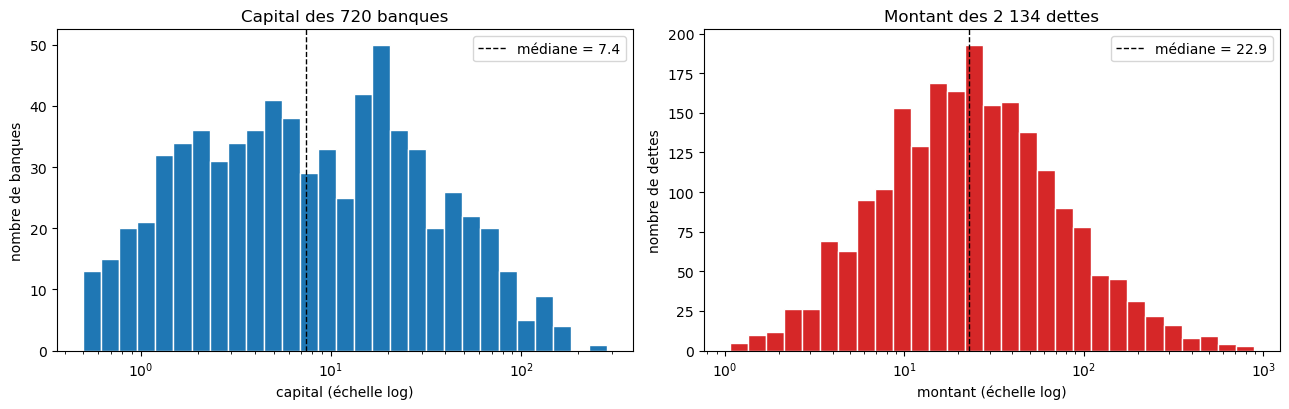

En moyenne, les 10 % des banques les plus capitalisées (6 sur 60) détiennent 44% du capital de leur réseau.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins_cap = np.logspace(np.log10(banques["capital"].min()), np.log10(banques["capital"].max()), 30)
axes[0].hist(banques["capital"], bins=bins_cap, color="tab:blue", edgecolor="white")
axes[0].set_xscale("log")
axes[0].axvline(banques["capital"].median(), color="black", ls="--", lw=1,
                label=f"médiane = {banques['capital'].median():.1f}")
axes[0].set(title="Capital des 720 banques", xlabel="capital (échelle log)", ylabel="nombre de banques")
axes[0].legend()

bins_m = np.logspace(np.log10(expositions["montant"].min()), np.log10(expositions["montant"].max()), 30)
axes[1].hist(expositions["montant"], bins=bins_m, color="tab:red", edgecolor="white")
axes[1].set_xscale("log")
axes[1].axvline(expositions["montant"].median(), color="black", ls="--", lw=1,
                label=f"médiane = {expositions['montant'].median():.1f}")
axes[1].set(title="Montant des 2 134 dettes", xlabel="montant (échelle log)", ylabel="nombre de dettes")
axes[1].legend()
plt.tight_layout()
plt.show()

part_top10 = banques.groupby("reseau_id")["capital"].apply(lambda s: s.nlargest(6).sum() / s.sum()).mean()
print(f"En moyenne, les 10 % des banques les plus capitalisées (6 sur 60) détiennent {part_top10:.0%} du capital de leur réseau.")

- **Capitaux très inégaux :** de 0,5 à 282, avec une médiane de 7,4. L'axe est en échelle logarithmique, sinon la plupart des banques seraient écrasées contre zéro. Dans chaque réseau, les 6 banques les plus capitalisées détiennent en moyenne **44 %** du capital.
- **Dettes souvent grandes face aux capitaux :** le montant médian d'une dette (22,9) est **trois fois** le capital médian d'une banque (7,4). Une seule dette perdue peut donc suffire à faire tomber un créancier de taille moyenne, ce qui rend les cascades possibles.

## 2.4. Indicateurs par banque

,capital,d_in,d_out,w_in,w_out,fragilite
mean,18.92,2.96,2.96,134.84,134.84,6.12
50%,7.39,1.00,2.00,38.03,50.62,4.87
90%,51.02,10.00,9.00,413.78,417.93,13.42
max,281.96,26.00,17.00,1731.16,1349.34,46.37


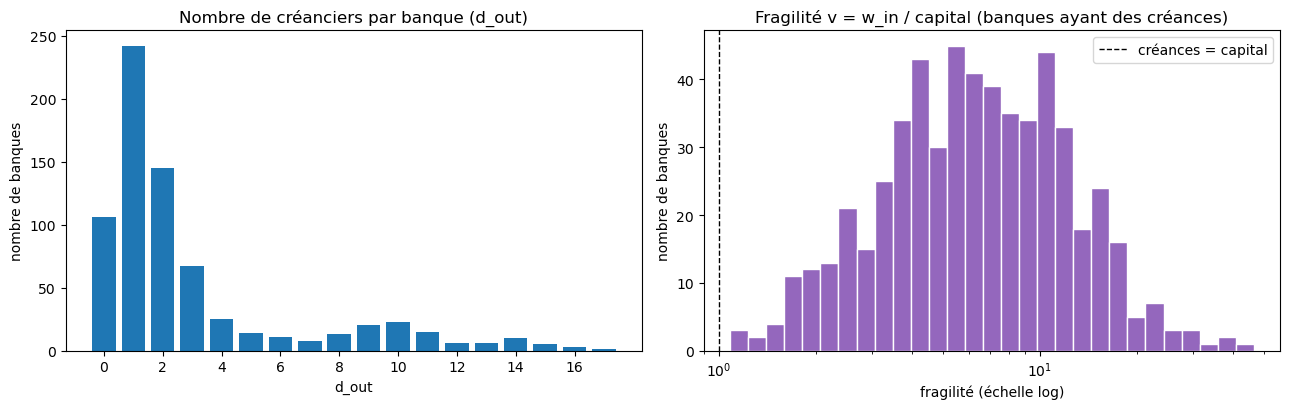

Banques isolées : 24
Part des banques dont les créances dépassent le capital (v > 1) : 78%
Part des banques avec au plus 2 créanciers : 68%


In [6]:
entrant = expositions.groupby(["reseau_id", "creancier_id"])["montant"].agg(d_in="count", w_in="sum")
sortant = expositions.groupby(["reseau_id", "debiteur_id"])["montant"].agg(d_out="count", w_out="sum")
entrant.index.names = sortant.index.names = ["reseau_id", "banque_id"]
noeuds = banques.set_index(["reseau_id", "banque_id"]).join(entrant).join(sortant).fillna(0)
noeuds["fragilite"] = noeuds["w_in"] / noeuds["capital"]

display(noeuds[["capital", "d_in", "d_out", "w_in", "w_out", "fragilite"]]
        .describe(percentiles=[0.5, 0.9]).loc[["mean", "50%", "90%", "max"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
compte = noeuds["d_out"].astype(int).value_counts().sort_index()
axes[0].bar(compte.index, compte.values, color="tab:blue")
axes[0].set_xticks(range(0, int(compte.index.max()) + 1, 2))
axes[0].set(title="Nombre de créanciers par banque (d_out)", xlabel="d_out", ylabel="nombre de banques")

f = noeuds.loc[noeuds["fragilite"] > 0, "fragilite"]
axes[1].hist(f, bins=np.logspace(np.log10(f.min()), np.log10(f.max()), 30), color="tab:purple", edgecolor="white")
axes[1].set_xscale("log")
axes[1].axvline(1, color="black", ls="--", lw=1, label="créances = capital")
axes[1].set(title="Fragilité v = w_in / capital (banques ayant des créances)", xlabel="fragilité (échelle log)", ylabel="nombre de banques")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Banques isolées :", int(((noeuds["d_in"] == 0) & (noeuds["d_out"] == 0)).sum()))
print("Part des banques dont les créances dépassent le capital (v > 1) :", f"{(noeuds['fragilite'] > 1).mean():.0%}")
print("Part des banques avec au plus 2 créanciers :", f"{(noeuds['d_out'] <= 2).mean():.0%}")

Rappel de la convention : `d_in` = nombre de débiteurs, `w_in` = **créances détenues** (ce que la banque peut perdre) ; `d_out` = nombre de créanciers, `w_out` = **dettes** (ce qu'elle fait perdre si elle tombe) ; fragilité $v = w_{in} / c$.

- **Deux populations de banques :** **68 %** des banques ont au plus 2 créanciers (une périphérie peu connectée), tandis qu'un petit groupe en a 8 à 17 (un cœur très connecté). Le graphique de gauche montre ces deux groupes. Le défaut d'une banque du cœur touche directement beaucoup d'autres banques.
- **Des banques très fragiles :** **78 %** des banques détiennent plus de créances que de capital ($v > 1$), et la moitié des banques ayant des créances détiennent environ 5 fois leur capital. Si leurs débiteurs ne remboursent qu'une partie de leurs dettes, beaucoup ne peuvent pas absorber la perte.
- **24 banques isolées** (1 à 3 par réseau) : elles ne prêtent ni n'empruntent, ne peuvent ni subir ni transmettre de pertes, mais restent dans le graphe car elles comptent dans N.

# PARTIE 3 : Explorer le réseau bancaire et simuler une cascade de défauts

## 3.1. Formuler des hypothèses à partir du graphe

60 banques, 140 dettes, densité = 0.04


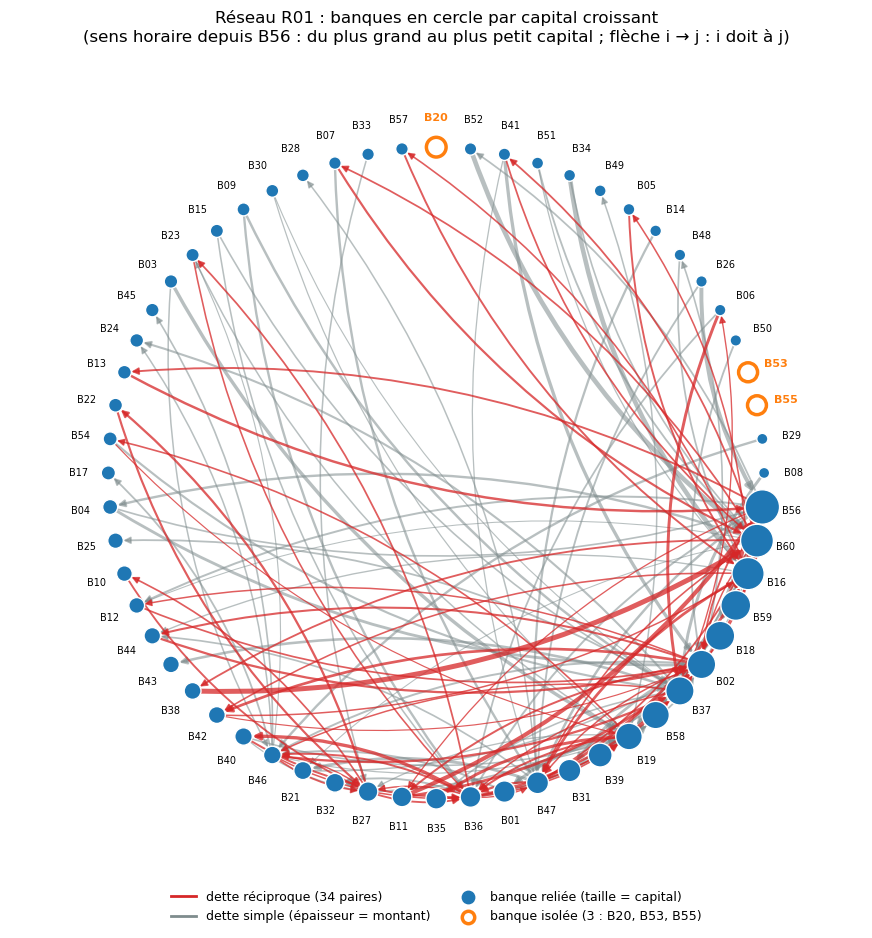

In [7]:
reseau = "R01"
G = nx.DiGraph()
G.add_nodes_from(banques.loc[banques["reseau_id"] == reseau, "banque_id"])
e = expositions[expositions["reseau_id"] == reseau]
G.add_weighted_edges_from(zip(e["debiteur_id"], e["creancier_id"], e["montant"]))

print(G.number_of_nodes(), "banques,", G.number_of_edges(), "dettes, densité =", round(nx.density(G), 3))

capital = banques[banques["reseau_id"] == reseau].set_index("banque_id")["capital"]

ordre = capital.sort_values().index
pos = nx.circular_layout(ordre)
pos_noms = {b: 1.09 * p for b, p in pos.items()}

isolees = [b for b in G.nodes if G.degree(b) == 0]
reliees = [b for b in G.nodes if G.degree(b) > 0]
reciproques = [(i, j) for i, j in G.edges if G.has_edge(j, i)]
simples = [(i, j) for i, j in G.edges if not G.has_edge(j, i)]

taille = {b: 60 + 6 * capital[b] for b in G.nodes}
w_max = max(d["weight"] for _, _, d in G.edges(data=True))
def epaisseur(liste):
    return [0.6 + 3 * np.sqrt(G[i][j]["weight"] / w_max) for i, j in liste]

fig, ax = plt.subplots(figsize=(11, 11))
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=simples, width=epaisseur(simples), edge_color="#7F8C8D",
                       alpha=0.55, arrowsize=10, connectionstyle="arc3,rad=0.15",
                       node_size=[taille[n] for n in G.nodes])
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=reciproques, width=epaisseur(reciproques), edge_color="tab:red",
                       alpha=0.75, arrowsize=10, connectionstyle="arc3,rad=0.15",
                       node_size=[taille[n] for n in G.nodes])
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=reliees, node_size=[taille[n] for n in reliees],
                       node_color="tab:blue", edgecolors="white", linewidths=1)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=isolees, node_size=[taille[n] + 120 for n in isolees],
                       node_color="white", edgecolors="tab:orange", linewidths=2.5)
nx.draw_networkx_labels(G, pos_noms, ax=ax, font_size=7, labels={b: b for b in reliees})
nx.draw_networkx_labels(G, pos_noms, ax=ax, font_size=8, font_color="tab:orange", font_weight="bold",
                        labels={b: b for b in isolees})

ax.plot([], [], color="tab:red", lw=2, label=f"dette réciproque ({len(reciproques) // 2} paires)")
ax.plot([], [], color="#7F8C8D", lw=2, label="dette simple (épaisseur = montant)")
ax.scatter([], [], s=80, color="tab:blue", label="banque reliée (taille = capital)")
ax.scatter([], [], s=80, color="white", edgecolors="tab:orange", linewidths=2.5,
           label=f"banque isolée ({len(isolees)} : {', '.join(isolees)})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, fontsize=9, frameon=False)
ax.set_title(f"Réseau {reseau} : banques en cercle par capital croissant\n"
             "(sens horaire depuis B56 : du plus grand au plus petit capital ; flèche i → j : i doit à j)", fontsize=12)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.axis("off")
plt.show()

### Hypothèses


**H1 : « Une dette réciproque est une dette perdue pour la contagion »**

Dans R01, 34 paires de banques se doivent mutuellement de l'argent (i doit à j **et** j doit à i). Intuitivement, ces boucles semblent dangereuses : on imagine un effet boule de neige où les pertes tournent en rond. Nous faisons l'hypothèse **inverse** : dans ce modèle, un défaut est **irréversible**. Si l'origine i fait tomber son créancier j, la dette que j doit à i ne fait plus perdre personne, puisque i est déjà en défaut : cette partie des dettes de j est « gaspillée » pour la propagation. Nous supposons donc que les **dettes réciproques n'amplifient pas la contagion**. À nombre de créanciers égal, une origine liée à ses créanciers par des dettes réciproques devrait même déclencher des cascades **plus petites**, car une partie du choc revient vers une banque déjà tombée.


**H2 : La taille de la banque qui fait défaut ne suffit pas à prédire l'ampleur de la cascade**

Quand une banque fait défaut, ses créanciers perdent une partie de ce qu'elle leur doit. Un créancier tombe à son tour si cette perte dépasse son capital.

Ce qui compte n'est donc pas la taille de la banque qui fait défaut, mais **ce qu'elle doit à chaque créancier comparé au capital de ce créancier** :
- une **petite banque** qui doit beaucoup à un créancier peu solide peut le faire tomber, et déclencher une grande cascade ;
- une **grande banque** qui doit peu à chacun de ses créanciers peut ne faire tomber personne.

Nous supposons donc qu'une petite banque peut provoquer une cascade aussi grande qu'une grande banque.

## 3.2. Appliquer la règle de la propagation

In [9]:
from mon_simulateur import construire_graphe, simuler

reseau = "R01"
G = construire_graphe(banques[banques["reseau_id"] == reseau],
                      expositions[expositions["reseau_id"] == reseau])
print("Sommets :", G.number_of_nodes(), "| arêtes :", G.number_of_edges())

defauts, etapes = simuler(G, "B02", 0.6)
print("Défauts :", len(defauts), "| nouveaux par étape :", etapes)

Sommets : 60 | arêtes : 140
Défauts : 45 | nouveaux par étape : [6, 4, 6, 10, 13, 5]


In [10]:
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import ipywidgets as widgets
from matplotlib.animation import FuncAnimation
from matplotlib.lines import Line2D
from IPython.display import HTML, display
from aides_contagion import depasse_capital

reseau = "R01"


def derouler_cascade(G, origine, lam):
    """Même règle que simuler, mais garde l'état du réseau à chaque étape (pour la figure)."""
    defauts = {origine}
    pertes = {}
    vague = [origine]
    etats = [{"defauts": set(defauts), "nouveaux": {origine}, "pertes": {}, "aretes": []}]
    while vague:
        touchees, aretes = set(), []
        for debiteur in vague:
            for creancier in G.successors(debiteur):
                if creancier in defauts:
                    continue
                pertes[creancier] = pertes.get(creancier, 0.0) + lam * G[debiteur][creancier]["montant"]
                touchees.add(creancier)
                aretes.append((debiteur, creancier))
        vague = [b for b in touchees if depasse_capital(pertes[b], G.nodes[b]["capital"])]
        if vague:
            defauts.update(vague)
            etats.append({"defauts": set(defauts), "nouveaux": set(vague),
                          "pertes": dict(pertes), "aretes": aretes})
    return etats

G = construire_graphe(banques[banques["reseau_id"] == reseau],
                      expositions[expositions["reseau_id"] == reseau])
pos = nx.spring_layout(G, seed=42, k=0.6)
noeuds = list(G.nodes)
tailles = [40 + 8 * G.nodes[b]["capital"] for b in noeuds]
N = G.number_of_nodes()

COULEURS = {"origine": "black", "nouveau": "tab:orange", "defaut": "tab:red",
            "touchee": "gold", "saine": "tab:green"}
LEGENDE = [
    Line2D([], [], marker="o", ls="", color=COULEURS["origine"], label="origine"),
    Line2D([], [], marker="o", ls="", color=COULEURS["nouveau"], label="défaut à cette étape"),
    Line2D([], [], marker="o", ls="", color=COULEURS["defaut"], label="défaut antérieur"),
    Line2D([], [], marker="o", ls="", color=COULEURS["touchee"], label="touchée mais résiste"),
    Line2D([], [], marker="o", ls="", color=COULEURS["saine"], label="aucune perte"),
    Line2D([], [], color="tab:red", label="perte transmise"),
]


def statut(b, etat, origine):
    if b == origine:
        return "origine"
    if b in etat["nouveaux"]:
        return "nouveau"
    if b in etat["defauts"]:
        return "defaut"
    if etat["pertes"].get(b, 0) > 0:
        return "touchee"
    return "saine"


def afficher_cascade(origine, lam):
    etats = derouler_cascade(G, origine, lam)
    defauts, etapes = simuler(G, origine, lam)
    assert etats[-1]["defauts"] == defauts
    assert [len(e["nouveaux"]) for e in etats[1:]] == etapes

    matplotlib.rcParams["animation.embed_limit"] = 50
    fig, ax = plt.subplots(figsize=(12, 8))

    def dessiner(k):
        ax.clear()
        etat = etats[k]
        nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15, edge_color="grey", arrowsize=6, node_size=tailles)
        if etat["aretes"]:   # dettes par lesquelles la perte se transmet à cette étape
            nx.draw_networkx_edges(G, pos, ax=ax, edgelist=etat["aretes"], edge_color="tab:red",
                                   width=1.5, arrowsize=10, node_size=tailles)
        nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=noeuds, node_size=tailles,
                               node_color=[COULEURS[statut(b, etat, origine)] for b in noeuds],
                               edgecolors="black", linewidths=0.5)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
        nouveaux = 0 if k == 0 else len(etat["nouveaux"])
        ax.set_title(f"{reseau}, origine {origine}, λ = {lam:.2f} — étape {k} / {len(etats) - 1} : "
                     f"{nouveaux} nouveau(x) défaut(s), {len(etat['defauts'])} au total")
        ax.legend(handles=LEGENDE, loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
        ax.axis("off")
        fig.tight_layout()

    anim = FuncAnimation(fig, dessiner, frames=len(etats), interval=1500)
    html = anim.to_jshtml()
    plt.close(fig)
    display(HTML(html))


    display(pd.DataFrame([{
        "etape": k,
        "nouveaux_defauts": ", ".join(sorted(e["nouveaux"])),
        "nb_nouveaux": 0 if k == 0 else len(e["nouveaux"]),
        "nb_defauts_total": len(e["defauts"]),
        "y_cumule": round((len(e["defauts"]) - 1) / (N - 1), 3),
    } for k, e in enumerate(etats)]))
    print(f"y = ({len(defauts)} - 1) / ({N} - 1) = {(len(defauts) - 1) / (N - 1):.3f}")

curseur_lam = widgets.FloatSlider(value=0.6, min=0.0, max=1.0, step=0.05,
                                  description="λ", continuous_update=False)
menu_origine = widgets.Dropdown(options=sorted(noeuds), value="B02", description="Origine")

widgets.interact_manual(afficher_cascade, origine=menu_origine, lam=curseur_lam);

interactive(children=(Dropdown(description='Origine', index=1, options=('B01', 'B02', 'B03', 'B04', 'B05', 'B0…

In [11]:
verifier(simuler, construire_graphe)

Vérification de simuler (module mon_simulateur) et de construire_graphe
----------------------------------------------------------------------------------------------------
✅ Test 1 - Exemple A-B-C (λ = 0,5, origine A)
✅ Test 2 - Aucun défaut secondaire (λ = 0, réseau sans arête, capitaux élevés)
✅ Test 3 - Perte égale au capital (inégalité stricte, piège des flottants)
✅ Test 4 - Défauts simultanés (S -> X, Y -> Z)
✅ Test 5 - Monotonie : plus de capital ne crée jamais plus de défauts
✅ Test 6 - Sens des arêtes (A doit à B)
✅ Test 7 - Pas de double comptage des pertes
✅ Test 8 - Origine imposée et banques isolées
✅ Test 9 - Irréversibilité et arrêt (propriétés sur des réseaux aléatoires)
----------------------------------------------------------------------------------------------------
Bilan : 9/9 tests réussis.


True

# PARTIE 4 : Ajoutez une composante de machine learning

## 4.1. La table des scénarios et la cible y 

Une ligne par triplet (réseau, banque d’origine, λ), avec λ ∈ {0,3 ; 0,6 ; 0,9}, soit 12 × 60 × 3 = 2 160 scénarios. Le simulateur fournit y et `generer_scenarios` organise les calculs.

In [12]:
from aides_contagion import generer_scenarios, references_medianes, predire_references
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
scenarios = generer_scenarios(banques, expositions, construire_graphe, simuler,
                              lambdas=(0.3, 0.6, 0.9), repartition=repartitions)

assert len(scenarios) == 12 * 60 * 3 == 2160
print(scenarios.shape)
scenarios[["reseau_id", "usage", "origine", "lambda", "n_defauts", "y"]].head()

[############################] 100.0 %  720/720 origines  R12          0 s écoulées, ~0 s restantes   
2160 scénarios simulés (12 réseau(x), 3 valeur(s) de λ) en 0.2 s.
(2160, 9)


,reseau_id,usage,origine,lambda,n_defauts,y
0,R01,apprentissage,B01,0.3,1,0.000000
1,R01,apprentissage,B01,0.6,5,0.067797
2,R01,apprentissage,B01,0.9,5,0.067797
3,R01,apprentissage,B02,0.3,4,0.050847
4,R01,apprentissage,B02,0.6,45,0.745763


L’assert vérifie qu’on a bien les 2 160 scénarios. Chaque banque sert d’origine une fois pour chaque λ.

## 4.2. Les variables explicatives

**Consigne :** au minimum λ, le capital de l'origine, ses degrés entrant et sortant et ses poids entrant et sortant, plus une ou deux variables motivées dont le calcul est défini. Les identifiants et les résultats de la cascade sont interdits.

Toutes les variables sont calculées sur le réseau initial, avant la cascade. Elles décrivent la banque d'origine du scénario et l'intensité du choc.

| Variable | Définition | Calcul précis | Interprétation |
|---|---|---|---|
| `lambda` | Fraction de perte $\lambda$ | Valeur du scénario : 0,3 ; 0,6 ou 0,9 | Intensité du choc : part de chaque dette perdue par le créancier |
| `capital` | Capital de l'origine | $c_{origine}$ | Taille de la banque ; ne la protège pas du défaut initial, qui est imposé |
| `d_in` | Degré entrant | Nombre d'arêtes $i \to origine$ | Nombre de débiteurs de l'origine |
| `d_out` | Degré sortant | Nombre d'arêtes $origine \to k$ | Nombre de créanciers de l'origine, c'est-à-dire de banques qui subissent une perte directe |
| `w_in` | Poids entrant | $\sum_i e_{i,origine}$ | Créances détenues par l'origine |
| `w_out` | Poids sortant | $\sum_k e_{origine,k}$ | Dettes de l'origine : montant total exposé à son défaut |
| `atteignables_2` | Banques atteignables en deux relations *(variable ajoutée)* | Nombre de banques distinctes, origine exclue, parmi ses créanciers directs et les créanciers de ces créanciers (sens des pertes) | Étendue du voisinage que le choc peut toucher en deux étapes |
| `pression_creanciers` | Pression sur les créanciers directs *(variable ajoutée)* | $\dfrac{\sum_j e_{origine,j}}{\sum_j c_j}$, sommes sur les créanciers directs $j$ de l'origine ; 0 si elle n'en a aucun | Dettes de l'origine rapportées au capital total de ceux qui les détiennent : plus elle est élevée, plus les premières pertes risquent de dépasser les capitaux |

**Pourquoi ces deux variables ajoutées ?** Une perte ne circule que du débiteur vers le créancier, et une banque fait défaut quand sa perte dépasse son capital. `atteignables_2` mesure combien de banques le choc peut atteindre rapidement, et `pression_creanciers` avec quelle force il frappe les premières touchées, comparé à leur capacité d'absorption.

**Variables exclues :**
- **Identifiants** (`reseau_id`, `origine`) : elles servent seulement au suivi et à la fusion des tables.
- **Résultats de la cascade** (`n_defauts`, `n_etapes`, `nouveaux_par_etape`, `defauts_finaux`) : ce serait une fuite d'information, puisque le modèle doit prédire $y$ avant de lancer la cascade. Pour la même raison, on n'utilise pas le nombre de créanciers dont la perte dépasserait le capital pour un $\lambda$ donné : ce serait exactement le nombre de défauts à la première étape.

In [13]:
def variables_reseau(G):
    """Variables de chaque banque, calculées sur le réseau INITIAL (avant toute cascade)."""
    lignes = []
    for b in G.nodes:
        creanciers = list(G.successors(b))
        dettes = [G[b][j]["montant"] for j in creanciers]
        capitaux = [G.nodes[j]["capital"] for j in creanciers]
        atteintes = set(creanciers)
        for j in creanciers:
            atteintes.update(G.successors(j))
        atteintes.discard(b)
        lignes.append({
            "origine": b,
            "capital": G.nodes[b]["capital"],
            "d_in": G.in_degree(b),
            "d_out": G.out_degree(b),
            "w_in": G.in_degree(b, weight="montant"),
            "w_out": G.out_degree(b, weight="montant"),
            "atteignables_2": len(atteintes),
            "pression_creanciers": sum(dettes) / sum(capitaux) if creanciers else 0.0,
        })
    return pd.DataFrame(lignes)


morceaux = []
for r in sorted(banques["reseau_id"].unique()):
    G_r = construire_graphe(banques[banques["reseau_id"] == r],
                            expositions[expositions["reseau_id"] == r])
    morceaux.append(variables_reseau(G_r).assign(reseau_id=r))
variables_banques = pd.concat(morceaux, ignore_index=True)

table = scenarios.merge(variables_banques, on=["reseau_id", "origine"], how="left")

VARIABLES = ["lambda", "capital", "d_in", "d_out", "w_in", "w_out",
             "atteignables_2", "pression_creanciers"]

INTERDITES = ["reseau_id", "origine", "usage", "y", "n_defauts", "n_etapes",
              "nouveaux_par_etape", "defauts_finaux"]
assert not set(VARIABLES) & set(INTERDITES)
assert table[VARIABLES].notna().all().all()
table[["reseau_id", "origine", "y"] + VARIABLES].head()

,reseau_id,origine,y,lambda,capital,d_in,d_out,w_in,w_out,atteignables_2,pression_creanciers
0,R01,B01,0.000000,0.3,29.68,1,1,159.26,43.54,9,2.576331
1,R01,B01,0.067797,0.6,29.68,1,1,159.26,43.54,9,2.576331
2,R01,B01,0.067797,0.9,29.68,1,1,159.26,43.54,9,2.576331
3,R01,B02,0.050847,0.3,59.52,13,10,662.50,449.87,29,1.396158
4,R01,B02,0.745763,0.6,59.52,13,10,662.50,449.87,29,1.396158


`reseau_id` et `origine` ne servent qu’à fusionner les tables. Le premier `assert` vérifie qu’aucun identifiant ni aucun résultat de la cascade ne fait partie de VARIABLES.

## 4.3. La répartition fournie

8 réseaux pour l’apprentissage, 2 pour la validation, 2 pour le test. Tous les scénarios d’un réseau restent dans le même ensemble, sans partage aléatoire.

In [14]:
table = table.drop(columns="usage").merge(repartitions, on="reseau_id", how="left")

app  = table[table["usage"] == "apprentissage"]
val  = table[table["usage"] == "validation"]
test = table[table["usage"] == "test"]

resume = (table.groupby("usage")
               .agg(nb_reseaux=("reseau_id", "nunique"),
                    reseaux=("reseau_id", lambda s: ", ".join(sorted(s.unique()))),
                    nb_scenarios=("reseau_id", "size"))
               .reindex(["apprentissage", "validation", "test"]))
display(resume)

assert table["usage"].notna().all()
assert (table.groupby("reseau_id")["usage"].nunique() == 1).all()
r_app, r_val, r_test = set(app["reseau_id"]), set(val["reseau_id"]), set(test["reseau_id"])
assert not (r_app & r_val) and not (r_app & r_test) and not (r_val & r_test)
assert (len(r_app), len(r_val), len(r_test)) == (8, 2, 2)
assert len(app) + len(val) + len(test) == len(table) == 2160

,nb_reseaux,reseaux,nb_scenarios
usage,,,
apprentissage,8,"R01, R03, R05, R06, R07, R08, R11, R12",1440
validation,2,"R04, R10",360
test,2,"R02, R09",360


Un partage aléatoire des lignes mettrait des scénarios d’un même réseau à la fois en apprentissage et en test. Le modèle aurait déjà vu le réseau, et on ne mesurerait pas sa capacité à traiter un réseau nouveau.

## 4.4. Les deux références, évaluées sur la validation

La médiane globale des cibles d’apprentissage, puis une médiane par λ, avec references_medianes. Le sujet demande aussi d’évaluer ces références sur la validation.

In [15]:
refs = references_medianes(app)
print("Médiane globale :", round(refs["globale"], 4))
print("Médianes par λ  :", {lam: round(m, 4) for lam, m in refs["par_lambda"].items()})

val = table[table["usage"] == "validation"]
val = val.join(predire_references(refs, val))
print("MAE validation, médiane globale :", round(mean_absolute_error(val["y"], val["pred_globale"]), 4))
print("MAE validation, médiane par λ   :", round(mean_absolute_error(val["y"], val["pred_par_lambda"]), 4))

Médiane globale : 0.0
Médianes par λ  : {0.3: 0.0, 0.6: 0.0, 0.9: 0.0339}
MAE validation, médiane globale : 0.2974
MAE validation, médiane par λ   : 0.297


**Médiane globale = 0.** Plus de la moitié des scénarios d'apprentissage ont $y = 0$ : le défaut de l'origine ne provoque aucun défaut secondaire. La médiane des cibles est donc nulle, et la référence globale prédit « aucune contagion » pour tous les scénarios.

**Médianes par λ = 0 ; 0 ; 0,0339.** Même pour un choc fort, la majorité des scénarios restent sans contagion ou presque. Pour λ = 0,9, la médiane correspond à seulement 2 défauts secondaires ($2/59 \approx 0{,}034$). La médiane suffit à peine à traduire l'effet de l'intensité du choc, car la distribution de $y$ est très asymétrique : beaucoup de valeurs nulles et un groupe de grandes cascades.

**MAE en validation ≈ 0,297 pour les deux références.** Prédire 0 (ou presque) fait une erreur moyenne d'environ **30 points de pourcentage** sur la proportion de défauts secondaires. Cette erreur vient des grandes cascades que la médiane ignore complètement. Les deux réseaux de validation (R04 et R10) sont assez contagieux, surtout R04 : l'erreur y est donc élevée.

**Les deux références sont presque identiques** (0,2974 contre 0,2970). Connaître λ seul n'apporte presque rien avec une médiane. Si le modèle fait mieux, ce sera donc grâce aux **variables du réseau**, et pas seulement grâce à l'intensité du choc.

**Objectif pour le modèle :** obtenir une MAE de validation nettement inférieure à 0,297.

## 4.5. Choisir un réglage sur la validation

Nous utilisons une **forêt aléatoire** (300 arbres). Son réglage principal est la profondeur des arbres : 
- trop faible, le modèle est trop simple ;
- trop forte, il apprend par cœur.

Nous testons trois profondeurs (3, 5 et 8) et gardons celle qui se trompe le moins sur la validation.

In [16]:
GRAINE = 100
PROFONDEURS = [3, 5, 8]

choix = []
for profondeur in PROFONDEURS:
    foret = RandomForestRegressor(n_estimators=300, max_depth=profondeur, min_samples_leaf=5,
                                  random_state=GRAINE, n_jobs=-1)
    foret.fit(app[VARIABLES], app["y"])
    choix.append({"max_depth": profondeur,
                  "MAE_apprentissage": mean_absolute_error(app["y"], foret.predict(app[VARIABLES])),
                  "MAE_validation": mean_absolute_error(val["y"], foret.predict(val[VARIABLES]))})
choix = pd.DataFrame(choix)
display(choix.round(4))

,max_depth,MAE_apprentissage,MAE_validation
0,3,0.1339,0.1619
1,5,0.1071,0.1381
2,8,0.0867,0.1287


Plus les arbres sont profonds, plus l'erreur baisse, en apprentissage comme en validation : le modèle a besoin d'assez de questions pour repérer les situations à risque.

On retient la profondeur 8 qui donne la plus petite erreur en validation (0,129).

**Remarques :**
- Pas de surapprentissage : l'écart entre apprentissage et validation reste modéré (0,087 contre 0,129).
- Le modèle fait bien mieux que les références : 0,129 contre 0,297 pour les médianes, soit environ deux fois moins d'erreur sur des réseaux qu'il n'a jamais vus.

## 4.6. Figer le choix et entraîner le modèle final

Un seul modèle appris suffit.

Profondeur retenue : 8


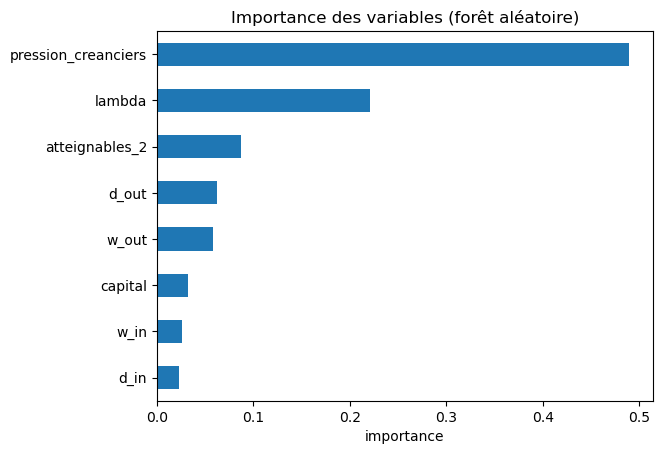

In [17]:
PROFONDEUR = int(choix.loc[choix["MAE_validation"].idxmin(), "max_depth"])
print("Profondeur retenue :", PROFONDEUR)

modele = RandomForestRegressor(n_estimators=300, max_depth=PROFONDEUR, min_samples_leaf=5,
                               random_state=GRAINE, n_jobs=-1)
modele.fit(app[VARIABLES], app["y"])

importances = pd.Series(modele.feature_importances_, index=VARIABLES).sort_values()
importances.plot(kind="barh", title="Importance des variables (forêt aléatoire)")
plt.xlabel("importance")
plt.show()

**Interprétation.**

L'importance mesure à quel point chaque variable sert au modèle pour découper les scénarios et réduire l'erreur. Les importances sont normalisées : leur somme vaut 1.
- `pression_creanciers` (≈ 0,49) : de loin la variable la plus utile. Elle compte à elle seule pour près de la moitié de l'importance totale. C'est cohérent avec la règle du simulateur : un créancier fait défaut quand sa perte dépasse son capital. Comparer les dettes de l'origine au capital de ses créanciers mesure directement si le choc a des chances de franchir ce seuil dès la première étape.
- `lambda` (≈ 0,22) : deuxième variable. L'intensité du choc multiplie toutes les pertes : une même structure de réseau peut ne rien déclencher à λ = 0,3 et provoquer une grande cascade à λ = 0,9. Le modèle a besoin de λ pour savoir si la pression sur les créanciers suffit à faire tomber le premier relais.
- `atteignables_2` (≈ 0,09) : un apport secondaire mais réel. Une fois le premier seuil franchi, le nombre de banques à portée en deux relations indique jusqu'où la cascade peut s'étendre.
- `d_out` et `w_out` (≈ 0,06 chacune) : peu utilisées. Leur information est en grande partie déjà contenue dans `pression_creanciers`, qui reprend `w_out` au numérateur et dépend des créanciers comptés par `d_out`. Le modèle préfère le ratio, plus directement lié au mécanisme de défaut.
- `capital`, `w_in`, `d_in` (≤ 0,03) : quasiment inutiles. Le défaut de l'origine est imposé, donc son capital ne la protège pas et n'influence pas la propagation ;`w_in` et `d_in` décrivent ce que les autres doivent à l'origine. Or les pertes circulent du débiteur vers le créancier : quand l'origine fait défaut, ses débiteurs ne perdent rien.


## 4.7. Évaluation finale sur le test, globale et par réseau

Le test sert une seule fois, une fois les choix arrêtés, pour comparer le modèle aux deux références. On présente la MAE globale et par réseau.

In [18]:
test = table[table["usage"] == "test"].copy()
test["pred_modele"] = modele.predict(test[VARIABLES])
test = test.join(predire_references(refs, test))

METHODES = {"Médiane globale": "pred_globale",
            "Médiane par λ": "pred_par_lambda",
            "Forêt aléatoire": "pred_modele"}

def tableau_mae(df):
    return pd.Series({nom: mean_absolute_error(df["y"], df[col]) for nom, col in METHODES.items()})

mae_test = pd.DataFrame({"Global (test)": tableau_mae(test)})
for r, g in test.groupby("reseau_id"):
    mae_test[r] = tableau_mae(g)
display(mae_test.T.round(4))

mae_lambda = pd.DataFrame({f"λ = {lam}": tableau_mae(g) for lam, g in test.groupby("lambda")})
display(mae_lambda.T.round(4))

,Médiane globale,Médiane par λ,Forêt aléatoire
Global (test),0.1999,0.1994,0.1019
R02,0.0798,0.0815,0.1007
R09,0.3200,0.3173,0.1032


,Médiane globale,Médiane par λ,Forêt aléatoire
λ = 0.3,0.0445,0.0445,0.0584
λ = 0.6,0.2333,0.2333,0.1353
λ = 0.9,0.3219,0.3205,0.1121


**Interprétation.**

- **Global :** la forêt se trompe en moyenne de 10,2 points de pourcentage sur y, contre environ 20 points pour les deux médianes. Elle divise donc l'erreur par deux sur l'ensemble du test.

- **Par réseau, deux situations opposées :**
  - **R09 (très contagieux) :** gain très net, de 0,320 à 0,103 (environ trois fois moins d'erreur). Les médianes prédisent « pas de contagion » alors que les grandes cascades y sont fréquentes ; la forêt les repère en grande partie.
  - **R02 (peu contagieux) :** la forêt fait moins bien que les médianes (0,101 contre 0,080). La plupart des chocs n'y déclenchent rien, et prédire 0 suffit presque toujours. La forêt, entraînée sur des réseaux plus contagieux, prédit parfois des cascades qui n'ont pas lieu (par exemple B54 et B50, cellule 9).

  Le gain global vient donc entièrement de R09. Sur R02, il n'est pas confirmé : la performance dépend fortement du réseau.

- **Par valeur de λ :**
  - **λ = 0,3 :** la forêt fait moins bien que la médiane (0,058 contre 0,045). Les cascades y sont rares et petites ; prédire 0 est presque toujours juste.
  - **λ = 0,6 et 0,9 :** la forêt fait nettement mieux (0,135 contre 0,233, puis 0,112 contre 0,321). C'est là que les grandes cascades apparaissent et que les variables du réseau deviennent utiles.

- **Médiane par λ :** elle n'apporte presque rien par rapport à la médiane globale (0,1994 contre 0,1999), car la médiane vaut 0 ou presque pour chaque λ. Le gain de la forêt vient donc des variables du réseau, et pas seulement de l'intensité du choc.

- **Limite :** cette évaluation repose sur deux réseaux seulement, aux comportements très différents. On ne peut pas en conclure que le modèle ferait mieux que la médiane sur n'importe quel nouveau réseau ; sur un réseau peu contagieux comme R02, la référence simple reste préférable.

## 4.8. Prédictions face aux valeurs simulées, et histogramme de y

Un graphique des prédictions face aux valeurs simulées et un histogramme de y, qui peuvent partager une figure.

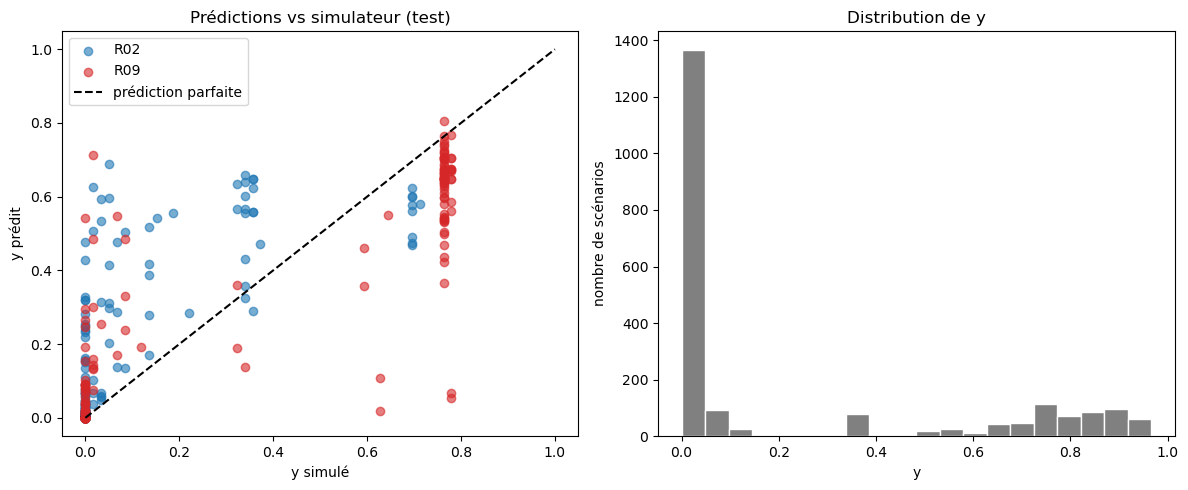

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for r, couleur in zip(sorted(r_test), ["tab:blue", "tab:red"]):
    t = test[test["reseau_id"] == r]
    axes[0].scatter(t["y"], t["pred_modele"], alpha=0.6, color=couleur, label=r)
axes[0].plot([0, 1], [0, 1], "k--", label="prédiction parfaite")
axes[0].set_xlabel("y simulé")
axes[0].set_ylabel("y prédit")
axes[0].set_title("Prédictions vs simulateur (test)")
axes[0].legend()

axes[1].hist(table["y"], bins=20, color="grey", edgecolor="white")
axes[1].set_xlabel("y")
axes[1].set_ylabel("nombre de scénarios")
axes[1].set_title("Distribution de y")

plt.tight_layout()
plt.show()


- **Prédictions face aux valeurs simulées (test) :** un point sur la diagonale est une prédiction parfaite. Au-dessus, le modèle surestime la cascade ; en dessous, il la sous-estime. Les erreurs ne sont pas du même type selon le réseau :
  - **R02 (en bleu) : surtout des surestimations.** Beaucoup de scénarios sans contagion ou presque (y simulé proche de 0) sont prédits entre 0,2 et 0,7, et le petit groupe de cascades vers y ≈ 0,35 est prédit autour de 0,6. Le modèle voit des cascades là où le réseau les arrête.
  - **R09 (en rouge) : surtout des sous-estimations.** Les grandes cascades (y ≈ 0,76 à 0,78) sont bien repérées dans l'ensemble, mais souvent un peu sous-estimées (prédites entre 0,4 et 0,7). Quelques-unes sont même prédites proches de 0 (points en bas à droite, comme B44).

Le modèle tire ses prédictions vers le milieu : il surestime les petites cascades et sous-estime les grandes. C'est typique d'un phénomène à seuil, que des variables moyennes décrivent mal.

- **Histogramme de y :** la distribution a deux pics.
  - **Un pic près de 0 :** environ 1 360 scénarios sur 2 150 ont y proche de 0 ; le choc reste limité à l'origine.
  - **Un second groupe de grandes cascades** entre 0,65 et 0,95.

  Entre les deux, presque rien, à part un petit groupe vers 0,35. Les cascades intermédiaires sont donc rares : soit la perte franchit le seuil d'une banque relais et la cascade emporte une grande partie du réseau, soit elle s'arrête tout de suite. Cette distribution explique en partie les erreurs du modèle : il voit peu d'exemples de cascades moyennes pour apprendre.

## 4.9. Commentaire des plus grosses erreurs

In [20]:
test["erreur"] = test["pred_modele"] - test["y"]
colonnes = ["reseau_id", "origine", "lambda", "y", "pred_modele", "erreur"] + VARIABLES[1:]
grosses_erreurs = (test.reindex(test["erreur"].abs().sort_values(ascending=False).index)[colonnes]
                       .rename(columns={"y": "y_simule", "pred_modele": "y_predit"}))
grosses_erreurs.head(8).round(3)

,reseau_id,origine,lambda,y_simule,y_predit,erreur,capital,d_in,d_out,w_in,w_out,atteignables_2,pression_creanciers
1570,R09,B44,0.6,0.780,0.054,-0.726,3.14,0,2,0.00,18.50,18,0.423
1571,R09,B44,0.9,0.780,0.067,-0.713,3.14,0,2,0.00,18.50,18,0.423
1480,R09,B14,0.6,0.017,0.712,0.695,14.41,10,10,239.70,323.75,36,0.854
341,R02,B54,0.9,0.051,0.690,0.639,2.70,1,1,7.13,102.43,9,2.103
329,R02,B50,0.9,0.017,0.627,0.610,45.53,8,6,299.01,620.82,27,1.544
1554,R09,B39,0.3,0.627,0.020,-0.608,17.86,1,2,149.09,137.67,14,1.842
248,R02,B23,0.9,0.034,0.593,0.559,3.60,0,1,0.00,67.45,7,1.481
340,R02,B54,0.6,0.051,0.597,0.546,2.70,1,1,7.13,102.43,9,2.103


**Analyse des deux plus grosses erreurs.**

- **Erreur 1 : R09, origine B44, λ = 0,6 : prédit 0,03, simulé 0,78 (forte sous-estimation)**

Vue par le modèle, B44 semble inoffensive : capital de 3,1, aucun débiteur, 2 créanciers, 18,5 de dettes, et une `pression_creanciers` faible (0,42) : ses dettes ne représentent que 42 % du capital total de ses créanciers. Le modèle prédit donc « pas de contagion ».

Dans la simulation, ses deux créanciers sont très différents. B33 est solide (capital 34,9) et ne perd que 0,7. Mais B48 reçoit l'essentiel de la dette (17,4) : sa perte de $0{,}6 \times 17{,}4 = 10{,}4$ dépasse son capital de 8,8 et il fait défaut. Or B48 a 10 créanciers et sert de relais vers le cœur du réseau. La cascade dure 7 étapes (1, 2, 7, 13, 14, 8 puis 1 nouveaux défauts) et emporte 46 banques, soit $y = 46/59 \approx 0{,}78$.

**Leçon :** `pression_creanciers` est un ratio global. Le capital élevé de B33 « dilue » la pression et masque que B48, le créancier le plus exposé, est précisément celui qui tombe. Une moyenne ne voit pas un seuil franchi par un créancier en particulier.

- **Erreur 2 : R02, origine B54, λ = 0,9 : prédit 0,70, simulé 0,05 (forte surestimation)**

Vue par le modèle, B54 semble très dangereuse : `pression_creanciers` = 2,10, puisque sa dette de 102,4 envers son unique créancier B60 vaut plus du double du capital de celui-ci (48,7). Le modèle a appris qu'une pression forte annonce une grande cascade.

Dans la simulation, B60 fait bien défaut (perte de 92,2). Mais seuls deux de ses 9 créanciers tombent à leur tour : B28, qui n'a aucun créancier, et B36, dont les créanciers résistent. La cascade s'arrête après 3 défauts secondaires, soit $y = 3/59 \approx 0{,}05$.

**Leçon :** une forte pression garantit que le premier relais tombe, pas que la cascade continue. Tout dépend de ce qui se trouve derrière ce relais : ici, des banques sans créanciers ou bien capitalisées, qui arrêtent la propagation.


- **Bilan :** ces deux erreurs viennent du même mécanisme. La cascade fonctionne par seuils, banque par banque, alors que les variables résument le voisinage par des totaux et des ratios globaux. Le modèle ne voit ni quel créancier précis franchit son seuil (B44), ni si la propagation peut continuer au-delà du premier relais (B54).

## 4.10 Conclusion de la partie Machine Learning 

**Ce que fait le modèle.** Une forêt aléatoire (300 arbres, profondeur 8 choisie sur la validation, graine 100) prédit la proportion de défauts secondaires $y$ avant de lancer la cascade. Elle n'utilise que des informations du réseau initial : l'intensité du choc $\lambda$, les caractéristiques de la banque d'origine (capital, degrés, poids) et deux variables ajoutées sur son voisinage, `atteignables_2` et `pression_creanciers`.

**Résultat.** Sur les deux réseaux de test, la MAE est de 0,102, contre 0,199 pour la médiane par λ : l'erreur moyenne passe d'environ 20 à 10 points de pourcentage. Le modèle s'appuie surtout sur `pression_creanciers` et sur $\lambda$, ce qui est cohérent avec la règle du simulateur : une banque fait défaut quand sa perte dépasse son capital.

**Limites de généralisation :**
- **Deux réseaux de test seulement.** L'évaluation repose sur R02 et R09, deux réseaux issus du même générateur que ceux de l'apprentissage. C'est un échantillon trop petit pour garantir la performance sur un nouveau réseau.
- **Un gain qui dépend du réseau.** Le gain vient entièrement de R09, réseau contagieux (MAE de 0,32 à 0,10). Sur R02, peu contagieux, le modèle fait moins bien que la simple médiane (0,101 contre 0,080) : il prédit des cascades qui n'ont pas lieu. De même, à λ = 0,3, prédire 0 reste plus précis que le modèle.
- **Des variables locales face à un phénomène à seuil.** La cascade dépend de seuils franchis banque par banque, parfois au-delà de deux relations (un relais fragile comme B48). Les variables résument le voisinage proche par des totaux et des ratios : elles ne voient ni quel créancier précis tombe, ni si la propagation continue après le premier relais (erreurs B44 et B54).
- **Peu de cascades intermédiaires.** La distribution de $y$ est concentrée près de 0 et vers 0,7–0,9. Avec peu d'exemples entre les deux, le modèle apprend mal ces cas et tire ses prédictions vers le milieu.
- **Un autre type de réseau pourrait tout changer.** Un réseau construit autrement (plus dense, plus concentré, avec d'autres capitaux) pourrait donner des résultats très différents, en mieux ou en moins bien.

**Conclusion.** Le modèle donne une approximation utile du simulateur sur les réseaux où la contagion est forte, mais il ne le remplace pas. Il ne s'agit pas de prévoir une crise réelle. Comme le précise le sujet, un gain de performance n'est ni garanti ni exigé : ce qui compte, c'est que le protocole soit respecté et que les erreurs soient comprises.

# PARTIE 5 : Comparer des stratégies de protection

La cellule de supervision peut renforcer le capital de quelques banques avant de connaître l'origine du choc.

- **Budget :** pour chaque réseau, $B = 0{,}10 \times \sum_j c_j$, calculé sur les capitaux initiaux.
- **Répartition :** $k = 5$ banques reçoivent chacune $B/5$. Les dettes et la règle de propagation ne changent pas.
- **Défaut initial toujours imposé :** même renforcée, la banque d'origine fait défaut. Le renforcement n'agit que sur la contagion secondaire.

| Situation | Banques renforcées |
|---|---|
| **Sans intervention** | aucune : capitaux initiaux |
| **Aléatoire** | 5 banques tirées au sort sans remise, 10 tirages officiels (`tirages_aleatoires.csv`, graines 0 à 9) |
| **Ciblée** | 5 banques choisies par une règle fondée sur le réseau avant le choc |

**Protocole, pour une comparaison équitable :**
1. La règle ciblée est conçue sur les 10 réseaux d'apprentissage et de validation, puis figée.
2. Elle est ensuite appliquée une seule fois aux 2 réseaux de test (R02, R09).
3. Pour chaque réseau, les banques renforcées sont choisies une seule fois, puis la stratégie est évaluée sur les mêmes 60 origines × 3 valeurs de λ (180 scénarios) que les autres.

Les aides `capitaux_renforces` et `comparer_interventions` gèrent le budget et les répétitions ; `resumer_interventions` calcule $y$ moyen, la plus grande cascade et le gain en points de pourcentage.

## 5.1. Règles candidates

Idée directrice : renforcer une banque n'est utile que si elle est susceptible de subir des pertes et de les transmettre. Une banque fragile sans créancier tombe, mais n'entraîne personne ; une banque solide ne tombe pas, quoi qu'on fasse.

Les règles reprennent les variables de la partie 4, mais appliquées à la banque qui reçoit le choc plutôt qu'à celle qui le déclenche :

- la fragilité $v_j = \sum_i e_{ij} / c_j$ est la pression que subit $j$ : ses créances rapportées à son capital. C'est le pendant de `pression_creanciers`, qui mesure la pression qu'une banque exerce sur ses créanciers ;
- `d_out`, `atteignables_2` et `pression_creanciers` mesurent la capacité de $j$ à transmettre son défaut.

| Règle | Score $s_j$ | Intuition |
|---|---|---|
| `fragilite x d_out` | $v_j \times d^{sortant}_j$ | subit beaucoup **et** touche beaucoup de créanciers (piste du sujet) |
| `fragilite x pression_creanciers` | $v_j \times$ `pression_creanciers`$_j$ | subit beaucoup **et** frappe fort ses propres créanciers |
| `fragilite x atteignables_2` | $v_j \times$ `atteignables_2`$_j$ | subit beaucoup **et** atteint beaucoup de banques en deux relations |
| `fragilite seule` | $v_j$ | la banque la plus vulnérable |
| `plus gros debiteurs (w_out)` | $w^{sortant}_j$ | la banque dont le défaut fait perdre le plus |

**Classement et égalités :** on garde les 5 scores les plus élevés. En cas d'égalité, la banque au plus petit capital passe en premier (le même montant $B/5$ la renforce proportionnellement davantage), puis l'identifiant par ordre alphabétique, pour que le choix soit reproductible. Tous les scores se calculent sur le réseau initial, sans lancer de cascade.

In [21]:
from aides_contagion import comparer_interventions, resumer_interventions, charger_tirages

K = 5
PART_BUDGET = 0.10
tirages = charger_tirages("donnees/tirages_aleatoires.csv")


def scores_banques(G):
    """Indicateurs de chaque banque, calculés sur le réseau INITIAL (avant tout choc)."""
    lignes = []
    for b in G.nodes:
        creanciers = list(G.successors(b))
        atteintes = set(creanciers)
        for j in creanciers:
            atteintes.update(G.successors(j))
        atteintes.discard(b)
        capital = G.nodes[b]["capital"]
        lignes.append({
            "banque_id": b,
            "capital": capital,
            "d_out": G.out_degree(b),
            "w_out": G.out_degree(b, weight="montant"),
            "fragilite": G.in_degree(b, weight="montant") / capital,          # v_j = w_in / c_j
            "atteignables_2": len(atteintes),
            "pression_creanciers": (sum(G[b][j]["montant"] for j in creanciers)
                                    / sum(G.nodes[j]["capital"] for j in creanciers)) if creanciers else 0.0,
        })
    t = pd.DataFrame(lignes)
    t["fragilite x d_out"] = t["fragilite"] * t["d_out"]
    t["fragilite x pression_creanciers"] = t["fragilite"] * t["pression_creanciers"]
    t["fragilite x atteignables_2"] = t["fragilite"] * t["atteignables_2"]
    t["fragilite seule"] = t["fragilite"]
    t["plus gros debiteurs (w_out)"] = t["w_out"]
    return t


def choisir_banques(G, regle, k=K):
    """Les k banques au score le plus élevé.
    Égalités départagées par le plus petit capital (le renforcement compte davantage),
    puis par l'identifiant (ordre alphabétique) pour que le choix soit reproductible."""
    t = scores_banques(G)
    t = t.sort_values([regle, "capital", "banque_id"], ascending=[False, True, True])
    return t["banque_id"].head(k).tolist()


def graphe_reseau(r):
    return construire_graphe(banques[banques["reseau_id"] == r],
                             expositions[expositions["reseau_id"] == r])


REGLES_CANDIDATES = ["fragilite x d_out", "fragilite x pression_creanciers",
                     "fragilite x atteignables_2", "fragilite seule", "plus gros debiteurs (w_out)"]

## 5.2. Choix de la règle sur les réseaux d'apprentissage et de validation

On compare les cinq règles et l'intervention aléatoire sur les réseaux d'apprentissage et de validation (8 d'apprentissage et 2 de validation).

In [22]:
reseaux_conception = sorted(repartitions.loc[repartitions["usage"].isin(["apprentissage", "validation"]),
                                             "reseau_id"])

morceaux = []
for r in reseaux_conception:
    G_r = graphe_reseau(r)
    strategies = {"sans": None,
                  "aleatoire": [tirages[(r, g)] for g in range(10)]}
    strategies.update({regle: choisir_banques(G_r, regle) for regle in REGLES_CANDIDATES})
    res_r = comparer_interventions(G_r, simuler, strategies, lambdas=(0.3, 0.6, 0.9), part_budget=PART_BUDGET)
    res_r.insert(0, "reseau_id", r)
    morceaux.append(res_r)
resultats_conception = pd.concat(morceaux, ignore_index=True)
resume_conception = resumer_interventions(resultats_conception)

gains_conception = (resume_conception.groupby("strategie")[["y_moyen", "y_max", "gain_pp"]].mean()
                    .drop(index="sans").sort_values("gain_pp", ascending=False))
display(gains_conception.round(3))

moy = resultats_conception.groupby(["reseau_id", "strategie", "repetition"])["y"].mean()
battus = pd.DataFrame({regle: {r: int((moy[r]["aleatoire"] > moy[r][regle].iloc[0]).sum())
                               for r in reseaux_conception}
                       for regle in REGLES_CANDIDATES})
print("Nombre de tirages aléatoires (sur 10) battus par chaque règle, réseau par réseau :")
display(battus)

,y_moyen,y_max,gain_pp
strategie,,,
fragilite x d_out,0.180,0.800,5.705
plus gros debiteurs (w_out),0.181,0.793,5.659
fragilite x atteignables_2,0.183,0.800,5.435
fragilite x pression_creanciers,0.183,0.780,5.431
fragilite seule,0.187,0.798,5.085
aleatoire,0.219,0.802,1.891


Nombre de tirages aléatoires (sur 10) battus par chaque règle, réseau par réseau :


,fragilite x d_out,fragilite x pression_creanciers,fragilite x atteignables_2,fragilite seule,plus gros debiteurs (w_out)
R01,10,10,10,10,10
R03,6,8,6,6,6
R04,10,10,10,10,10
R05,10,10,10,10,9
R06,6,6,6,3,8
R07,10,10,10,10,10
R08,10,7,10,10,8
R10,9,10,9,9,10
R11,10,10,10,10,10
R12,10,10,10,10,10


**Interprétation.**

**Tableau 1 : efficacité de chaque règle.** `gain_pp` indique de combien de points la règle réduit la part moyenne de banques qui font défaut, par rapport à « aucune intervention ».
- Les règles candidates réduisent les défauts de 5 à 6 points, contre 2 points pour le hasard.
- La meilleure est **`fragilite x d_out`** (5,7 points) : nous la retenons.

**Tableau 2 : la règle bat-elle le hasard ?** Dans chaque réseau, on compte combien des 10 tirages au hasard font moins bien que la règle (10 = la règle bat tous les tirages).
- `fragilite x d_out`, `fragilite x pression_creanciers`, `fragilite x atteignables_2`  bat les 10 tirages dans 7 réseaux sur 10, et au moins 6 tirages sur 10 dans les autres.
- `fragilite seule` bat les 10 tirages dans 7 réseaux sur 10, et au moins 3 tirages sur 10 dans les autres.
- `plus gros debiteurs (w_out)` bat les 10 tirages dans 6 réseaux sur 10, et au moins 6 tirages dans les autres.

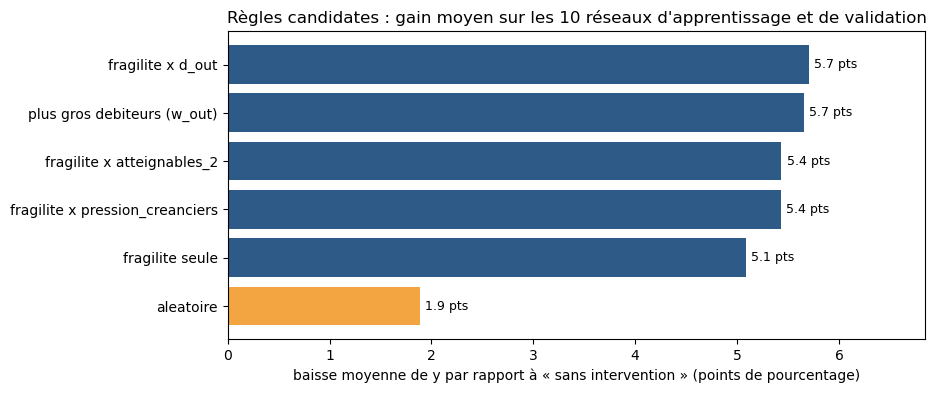

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
couleurs = ["#F2A541" if s == "aleatoire" else "#2E5A88" for s in gains_conception.index]
ax.barh(gains_conception.index[::-1], gains_conception["gain_pp"][::-1], color=couleurs[::-1])
for i, v in enumerate(gains_conception["gain_pp"][::-1]):
    ax.text(v + 0.05, i, f"{v:.1f} pts", va="center", fontsize=9)
ax.set_xlabel("baisse moyenne de y par rapport à « sans intervention » (points de pourcentage)")
ax.set_title("Règles candidates : gain moyen sur les 10 réseaux d'apprentissage et de validation")
ax.set_xlim(0, gains_conception["gain_pp"].max() * 1.2)
plt.show()

**Interprétation.** Chaque barre indique de combien de points la règle réduit la part moyenne de banques qui font défaut, par rapport à « aucune intervention », sur les 10 réseaux d'apprentissage et de validation. Plus la barre est longue, plus la règle est efficace.

Toutes les règles candidates (en bleu) font environ trois fois mieux que le hasard (en orange) : entre 5,1 et 5,7 points, contre 1,9.

- `fragilite seule` est la moins efficace des règles (5,1 points)
- `fragilite x d_out` arrive en tête (5,7 points), presque à égalité avec les plus gros débiteurs.

On choisit donc la règle `fragilite x d_out` qui obtient le meilleur gain moyen sur les 10 réseaux d'apprentissage et de validation.

## 5.3. Figer la règle et l'appliquer aux réseaux de test

In [24]:
REGLE_RETENUE = "fragilite x d_out"

reseaux_test = sorted(repartitions.loc[repartitions["usage"] == "test", "reseau_id"])
choix_test = {r: choisir_banques(graphe_reseau(r), REGLE_RETENUE) for r in reseaux_test}

for r, choisies in choix_test.items():
    print(f"{r} : banques renforcées = {', '.join(choisies)}")
    display(scores_banques(graphe_reseau(r)).set_index("banque_id")
            .loc[choisies, ["capital", "fragilite", "d_out", REGLE_RETENUE]].round(2))

R02 : banques renforcées = B10, B60, B53, B32, B58


,capital,fragilite,d_out,fragilite x d_out
banque_id,,,,
B10,72.21,9.24,14,129.36
B60,48.70,10.24,9,92.17
B53,25.63,9.99,9,89.92
B32,54.06,10.88,8,87.04
B58,132.39,8.66,9,77.92


R09 : banques renforcées = B31, B33, B14, B29, B25


,capital,fragilite,d_out,fragilite x d_out
banque_id,,,,
B31,19.42,17.66,14,247.19
B33,34.86,17.03,10,170.28
B14,14.41,16.63,10,166.34
B29,30.48,13.76,10,137.61
B25,26.61,13.77,9,123.94


**Interprétation.** La règle est figée et appliquée aux deux réseaux de test sans aucun ajustement. Pour chaque réseau, le tableau montre les 5 banques renforcées.

| | R02 | R09 |
|---|---|---|
| Banques renforcées | B10, B60, B53, B32, B58 | B31, B33, B14, B29, B25 |
| Nombre de créanciers (`d_out`) | 8 à 14 | 9 à 14 |
| Fragilité (créances / capital) | 9 à 11 | 14 à 18 |
| Capital | 26 à 132 | 14 à 35 |

- **Des banques très connectées :** toutes ont 8 à 14 créanciers, alors que la plupart des banques en ont 1 ou 2. Si elles tombent, beaucoup d'autres banques perdent de l'argent.
- **Des banques fragiles :** elles détiennent 9 à 18 fois leur capital en créances. Elles risquent donc de tomber dès que plusieurs de leurs débiteurs font défaut.

## 5.4. Évaluation finale sur les réseaux de test

On évalue les trois situations sur R02 et R09 : 
- sans intervention
- avec intervention aléatoire
- avec intervention ciblée

Les résultats sont comparés avec : 
- `y_moyen` : la moyenne de y sur les 180 scénarios (et sur les 10 tirages pour l’aléatoire)
- l'écart-type
- le minimum et le maximum : ils décrivent la dispersion entre tirages
- `gain_pp` : la baisse de $y$ moyen par rapport à « sans intervention », en points de pourcentage

In [25]:
morceaux = []
for r in reseaux_test:
    G_r = graphe_reseau(r)
    strategies = {"sans": None,
                  "aleatoire": [tirages[(r, g)] for g in range(10)],
                  "ciblee": choix_test[r]}
    res_r = comparer_interventions(G_r, simuler, strategies, lambdas=(0.3, 0.6, 0.9), part_budget=PART_BUDGET)
    res_r.insert(0, "reseau_id", r)
    morceaux.append(res_r)
resultats_test = pd.concat(morceaux, ignore_index=True)
resume_test = resumer_interventions(resultats_test)

colonnes = ["reseau_id", "strategie", "y_moyen", "y_moyen_ecart_type", "y_moyen_min", "y_moyen_max",
            "y_max", "gain_pp"]
display(resume_test[colonnes].round(3))

ensemble = resumer_interventions(resultats_test.drop(columns="reseau_id"))
display(ensemble[["strategie", "y_moyen", "y_moyen_ecart_type", "y_max", "gain_pp"]].round(3))

,reseau_id,strategie,y_moyen,y_moyen_ecart_type,y_moyen_min,y_moyen_max,y_max,gain_pp
0,R02,sans,0.080,NaN,0.080,0.080,0.712,0.000
1,R02,aleatoire,0.065,0.012,0.049,0.079,0.712,1.491
2,R02,ciblee,0.045,NaN,0.045,0.045,0.407,3.522
3,R09,sans,0.320,NaN,0.320,0.320,0.780,0.000
4,R09,aleatoire,0.305,0.010,0.281,0.317,0.780,1.466
5,R09,ciblee,0.250,NaN,0.250,0.250,0.780,7.015


,strategie,y_moyen,y_moyen_ecart_type,y_max,gain_pp
0,sans,0.200,NaN,0.78,0.000
1,aleatoire,0.185,0.006,0.78,1.478
2,ciblee,0.147,NaN,0.78,5.268


**Interprétation.**

La règle ciblée fait mieux que les 10 tirages aléatoires dans les deux réseaux de test. Donc, le résultat obtenu sur les ensembles d'apprentissage et de validation se confirme sur des réseaux nouveaux.
- **R02 (peu contagieux) :** la baisse est faible en points (3,5) car $y$ est déjà bas, mais elle est forte en proportion : $y$ moyen baisse de **44 %**. La plus grande cascade passe de 0,71 à 0,41.
- **R09 (très contagieux) :** le gain est le plus grand (7 points), mais la plus grande cascade reste à 0,78, car certaines origines atteignent le cœur du réseau par d'autres chemins que les cinq banques renforcées.

In [26]:
par_lambda = (resultats_test.groupby(["reseau_id", "lambda", "strategie"])["y"].mean()
              .unstack("strategie")[["sans", "aleatoire", "ciblee"]])
par_lambda["gain aleatoire (pts)"] = 100 * (par_lambda["sans"] - par_lambda["aleatoire"])
par_lambda["gain ciblee (pts)"] = 100 * (par_lambda["sans"] - par_lambda["ciblee"])
display(par_lambda.round(3))

strategie          sans  aleatoire  ciblee  gain aleatoire (pts)  \
reseau_id lambda                                                   
R02       0.3     0.010      0.009   0.008                 0.164   
          0.6     0.058      0.053   0.045                 0.500   
          0.9     0.171      0.133   0.082                 3.808   
R09       0.3     0.079      0.068   0.027                 1.076   
          0.6     0.409      0.388   0.275                 2.073   
          0.9     0.472      0.460   0.447                 1.249   

strategie         gain ciblee (pts)  
reseau_id lambda                     
R02       0.3                 0.282  
          0.6                 1.299  
          0.9                 8.983  
R09       0.3                 5.113  
          0.6                13.390  
          0.9                 2.542

Par valeur de λ, le gain dépend fortement de l'intensité du choc :
- **λ = 0,3 :** peu de cascades sans intervention, donc peu à gagner (moins de 0,3 point dans R02).
- **λ = 0,6 :** c'est là que l'intervention ciblée est la plus utile dans R09. Elle évite 13,4 points de défauts secondaires, contre 2,1 pour l'aléatoire.
- **λ = 0,9 :** c'est là que l'intervention ciblée est la plus utile dans R02. Elle évite 9 points de défauts secondaires, contre 3,8 pour l'aléatoire.

**Remarque.**

R09 à λ = 0,9 : le gain retombe à 2,5 points. Le choc est si fort que le renforcement de $B/5$ ne suffit plus à faire résister les banques visées : le budget est trop faible face à ce niveau de pertes.

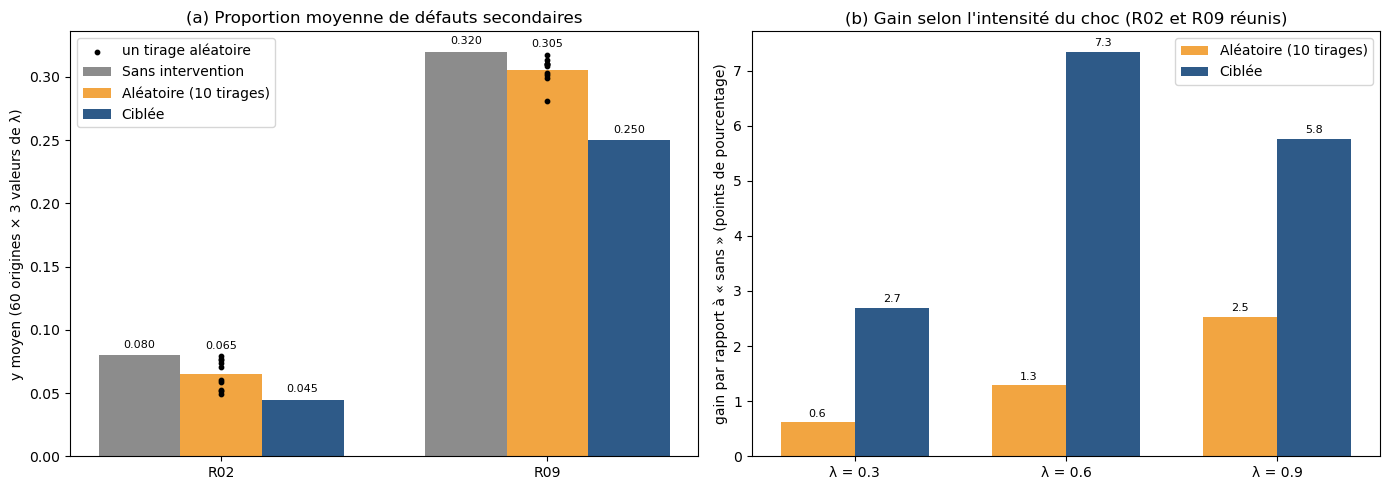

In [27]:
COULEURS = {"sans": "#8C8C8C", "aleatoire": "#F2A541", "ciblee": "#2E5A88"}
NOMS = {"sans": "Sans intervention", "aleatoire": "Aléatoire (10 tirages)", "ciblee": "Ciblée"}
ORDRE = ["sans", "aleatoire", "ciblee"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
largeur = 0.25
moy_tirages = resultats_test[resultats_test["strategie"] == "aleatoire"].groupby(["reseau_id", "repetition"])["y"].mean()
for i, s in enumerate(ORDRE):
    valeurs = [resume_test.query("reseau_id == @r and strategie == @s")["y_moyen"].iloc[0] for r in reseaux_test]
    x = np.arange(len(reseaux_test)) + (i - 1) * largeur
    ax.bar(x, valeurs, width=largeur, color=COULEURS[s], label=NOMS[s])
    for xi, v, r in zip(x, valeurs, reseaux_test):
        haut = moy_tirages[r].max() if s == "aleatoire" else v
        ax.text(xi, haut + 0.006, f"{v:.3f}", ha="center", fontsize=8)
for k, r in enumerate(reseaux_test):
    ax.scatter(np.full(10, k), moy_tirages[r], color="black", s=10, zorder=3,
               label="un tirage aléatoire" if k == 0 else None)
ax.set_xticks(range(len(reseaux_test)), reseaux_test)
ax.set_ylabel("y moyen (60 origines × 3 valeurs de λ)")
ax.set_title("(a) Proportion moyenne de défauts secondaires")
ax.legend()

ax = axes[1]
gain_lambda = (resultats_test.groupby(["lambda", "strategie"])["y"].mean().unstack("strategie"))
lambdas = gain_lambda.index.tolist()
for i, s in enumerate(["aleatoire", "ciblee"]):
    gains = 100 * (gain_lambda["sans"] - gain_lambda[s])
    x = np.arange(len(lambdas)) + (i - 0.5) * 0.35
    ax.bar(x, gains, width=0.35, color=COULEURS[s], label=NOMS[s])
    for xi, v in zip(x, gains):
        ax.text(xi, v + 0.1, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xticks(range(len(lambdas)), [f"λ = {lam}" for lam in lambdas])
ax.set_ylabel("gain par rapport à « sans » (points de pourcentage)")
ax.set_title("(b) Gain selon l'intensité du choc (R02 et R09 réunis)")
ax.legend()

plt.tight_layout()
plt.show()

**Graphique a.** Pour chaque réseau de test, la barre bleue (ciblée) est sous la barre orange (aléatoire) et sous tous les points noirs : aucun des 10 tirages aléatoires ne fait aussi bien que la règle ciblée. La dispersion des tirages montre que le hasard peut parfois bien tomber, mais rarement.

**Graphique b.** Sur les deux réseaux de test réunis, le gain de la stratégie ciblée vaut entre 2 et 6 fois celui de l'aléatoire selon λ. Il est maximal pour λ = 0,6 (7,3 points).

## 5.5. Prolongement : faire varier le budget

Le sujet fixe le budget à 10 % de la somme des capitaux. Nous regardons ce qui se passe avec un budget plus petit ou plus grand, de 2,5 % à 30 %.

On conserve la règle : `fragilite x d_out`.

reseau_id       R02              R09       
strategie aleatoire ciblee aleatoire ciblee
budget                                     
0.025           0.4    2.7       0.6    2.2
0.050           0.6    2.9       1.0    3.8
0.100           1.5    3.5       1.5    7.0
0.150           2.4    4.1       2.1    8.3
0.200           2.5    5.0       2.5    9.4
0.300           2.7    5.2       3.0   13.8

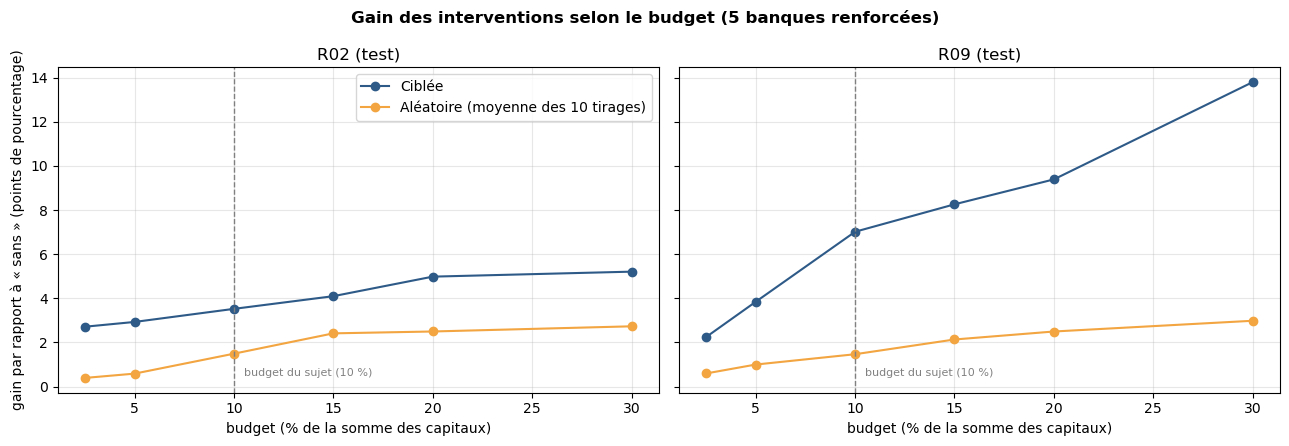

In [28]:
from aides_contagion import tirer_banques_aleatoires

BUDGETS = [0.025, 0.05, 0.10, 0.15, 0.20, 0.30]      # part de la somme des capitaux

lignes = []
for r in reseaux_test:
    G_r = graphe_reseau(r)
    strategies = {"sans": None,
                  "aleatoire": [tirages[(r, g)] for g in range(10)],
                  "ciblee": choisir_banques(G_r, REGLE_RETENUE)}      # mêmes 5 banques, seul le budget change
    for budget in BUDGETS:
        res = comparer_interventions(G_r, simuler, strategies, lambdas=(0.3, 0.6, 0.9), part_budget=budget)
        res.insert(0, "reseau_id", r)
        resume = resumer_interventions(res)
        for _, ligne in resume.iterrows():
            lignes.append({"reseau_id": r, "budget": budget, "strategie": ligne["strategie"],
                           "y_moyen": ligne["y_moyen"], "y_max": ligne["y_max"], "gain_pp": ligne["gain_pp"]})
effet_budget = pd.DataFrame(lignes)

display(effet_budget[effet_budget["strategie"] != "sans"]
        .pivot_table(index="budget", columns=["reseau_id", "strategie"], values="gain_pp").round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, r in zip(axes, reseaux_test):
    for s, couleur, nom in [("ciblee", "#2E5A88", "Ciblée"), ("aleatoire", "#F2A541", "Aléatoire (moyenne des 10 tirages)")]:
        d = effet_budget[(effet_budget["reseau_id"] == r) & (effet_budget["strategie"] == s)]
        ax.plot(100 * d["budget"], d["gain_pp"], marker="o", color=couleur, label=nom)
    ax.axvline(10, color="grey", ls="--", lw=1)
    ax.text(10.5, 0.5, "budget du sujet (10 %)", color="grey", fontsize=8)
    ax.set(title=f"{r} (test)", xlabel="budget (% de la somme des capitaux)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("gain par rapport à « sans » (points de pourcentage)")
axes[0].legend()
plt.suptitle("Gain des interventions selon le budget (5 banques renforcées)", fontweight="bold")
plt.tight_layout()
plt.show()

**Interprétation.**

- **Bien cibler compte plus que dépenser beaucoup.** Avec seulement 5 % du budget, la règle ciblée fait déjà mieux dans R09 que l'aléatoire avec 30 %. Dans R02, la règle ciblée à 2,5 % fait autant que l'aléatoire à 30 %.
- **Plus de budget aide surtout dans un réseau contagieux.** Dans R09, le gain continue de monter jusqu'à 30 % (quasiment 14 points). Dans R02, il plafonne vers 5 points : il y a peu de défauts à éviter au départ.
- **L'aléatoire progresse peu**, quel que soit le budget : renforcer des banques au hasard, même beaucoup, évite peu de cascades.

### Interface interactive

Cette interface permet de simuler soi-même une intervention et de voir immédiatement son effet sur la contagion. Trois réglages sont possibles :

- **Réseau :** n'importe lequel des 12 réseaux (apprentissage, validation ou test).
- **Budget :** la part de la somme des capitaux consacrée au renfort, de 0 à 30 % (10 % dans le sujet).
- **Nombre de banques renforcées :** de 1 à 10 (5 dans le sujet). Le budget est partagé à parts égales entre elles.

L'interface compare les trois situations (sans intervention, aléatoire, ciblée) sur les 180 scénarios du réseau, et affiche :
- la proportion moyenne de défauts secondaires de chaque stratégie, ainsi que le résultat de chacun des 10 tirages aléatoires ;
- cette même proportion pour chaque valeur de λ ;
- le gain de chaque stratégie, la plus grande cascade observée et la liste des banques renforcées par la règle ciblée.

In [29]:
import ipywidgets as widgets

USAGE = dict(zip(repartitions["reseau_id"], repartitions["usage"]))
NOMS = {"sans": "Sans intervention", "aleatoire": "Aléatoire (10 tirages)", "ciblee": "Ciblée"}
COULEURS = {"sans": "#8C8C8C", "aleatoire": "#F2A541", "ciblee": "#2E5A88"}


def explorer(reseau, budget_pct, k):
    G_r = graphe_reseau(reseau)
    ids = list(G_r.nodes)
    numero = int(reseau[1:])
    strategies = {"sans": None,
                  "aleatoire": [tirer_banques_aleatoires(ids, g, numero, k=k) for g in range(10)],
                  "ciblee": choisir_banques(G_r, REGLE_RETENUE, k=k)}
    res = comparer_interventions(G_r, simuler, strategies, lambdas=(0.3, 0.6, 0.9), part_budget=budget_pct / 100)
    resume = resumer_interventions(res).set_index("strategie")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    ax = axes[0]
    ordre = ["sans", "aleatoire", "ciblee"]
    ax.bar(range(3), [resume.loc[s, "y_moyen"] for s in ordre], color=[COULEURS[s] for s in ordre])
    tirages_moy = res[res["strategie"] == "aleatoire"].groupby("repetition")["y"].mean()
    ax.scatter(np.ones(len(tirages_moy)), tirages_moy, color="black", s=12, zorder=3, label="un tirage aléatoire")
    for i, s in enumerate(ordre):
        haut = tirages_moy.max() if s == "aleatoire" else resume.loc[s, "y_moyen"]
        ax.text(i, haut + 0.005, f"{resume.loc[s, 'y_moyen']:.3f}", ha="center", fontsize=9)
    ax.set_xticks(range(3), [NOMS[s] for s in ordre])
    ax.set(ylabel="y moyen", title="(a) Proportion moyenne de défauts secondaires")
    ax.legend()
    ax = axes[1]
    par_lambda = res.groupby(["lambda", "strategie"])["y"].mean().unstack()[ordre]
    for i, s in enumerate(ordre):
        ax.bar(np.arange(3) + (i - 1) * 0.27, par_lambda[s], width=0.27, color=COULEURS[s], label=NOMS[s])
    ax.set_xticks(range(3), [f"λ = {lam}" for lam in par_lambda.index])
    ax.set(ylabel="y moyen", title="(b) Selon l'intensité du choc")
    ax.legend()
    plt.suptitle(f"{reseau} ({USAGE[reseau]}) : budget = {budget_pct:.1f} % des capitaux, {k} banques renforcées",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"Gain de la stratégie ciblée   : {resume.loc['ciblee', 'gain_pp']:.1f} points")
    print(f"Gain de l'aléatoire (moyenne) : {resume.loc['aleatoire', 'gain_pp']:.1f} points")
    print(f"Plus grande cascade : sans = {resume.loc['sans', 'y_max']:.2f} | "
          f"aléatoire = {resume.loc['aleatoire', 'y_max']:.2f} | ciblée = {resume.loc['ciblee', 'y_max']:.2f}")
    print("Banques renforcées (ciblée) :", ", ".join(strategies["ciblee"]))


menu_reseau = widgets.Dropdown(options=[(f"{r} ({USAGE[r]})", r) for r in sorted(USAGE)], value="R09",
                               description="Réseau")
curseur_budget = widgets.FloatSlider(value=10, min=0, max=30, step=2.5, description="Budget (%)",
                                     continuous_update=False)
curseur_k = widgets.IntSlider(value=5, min=1, max=10, step=1, description="Banques",
                              continuous_update=False)

widgets.interact_manual(explorer, reseau=menu_reseau, budget_pct=curseur_budget, k=curseur_k);

interactive(children=(Dropdown(description='Réseau', index=8, options=(('R01 (apprentissage)', 'R01'), ('R02 (…

## 5.6. Conclusion 

**Recommandation.** À budget égal, il vaut mieux renforcer les banques à la fois fragiles et très connectées (règle `fragilite x d_out`) que de répartir l'aide au hasard.

- **Sur les réseaux de test**, cette règle réduit considérablement la part moyenne de défauts et fait mieux que chacun des 10 tirages.
- **Bien cibler compte plus que dépenser beaucoup :** avec 5 % des capitaux, la règle ciblée fait mieux que l'aléatoire avec 30 % (R09).
- **Prédire n'est pas protéger :** les banques à renforcer ne sont pas forcément les plus dangereuses quand elles tombent en premier, mais celles qui transmettent le choc.

**Limites :**
- **Deux réseaux de test seulement**, issus du même générateur : la conclusion reste à vérifier sur davantage de réseaux..
- **Les plus grandes cascades ne disparaissent pas toujours** (0,78 dans R09) : 5 banques ne suffisent pas à bloquer tous les chemins de contagion.
- **Modèle simplifié :** une cascade à seuil, sans paiements partiels ni réactions des marchés. Ce ne sont pas des prévisions sur des banques réelles.

# PARTIE 6 : Conclusion générale

## 6.1. Retour sur les hypothèses

Nous vérifions nos deux hypothèses de la partie 3 avec le simulateur, sur les réseaux d'apprentissage uniquement. Les origines sans créancier, qui ne propagent jamais rien, sont écartées.

In [30]:
lignes = []
for r in sorted(banques["reseau_id"].unique()):
    G_r = construire_graphe(banques[banques["reseau_id"] == r],
                            expositions[expositions["reseau_id"] == r])
    for b in G_r.nodes:
        creanciers = list(G_r.successors(b))
        lignes.append({
            "reseau_id": r, "origine": b,
            "capital": G_r.nodes[b]["capital"],
            "d_out": len(creanciers),
            # H1 : au moins un créancier qui doit aussi de l'argent à l'origine (dette réciproque)
            "dette_reciproque": any(G_r.has_edge(j, b) for j in creanciers),
            # H2 : plus grosse dette de l'origine rapportée au capital du créancier concerné
            "expo_relative_max": max((G_r[b][j]["montant"] / G_r.nodes[j]["capital"] for j in creanciers), default=0.0),
        })
hyp = (scenarios[scenarios["usage"] == "apprentissage"]
       .merge(pd.DataFrame(lignes), on=["reseau_id", "origine"]))
hyp = hyp[hyp["d_out"] > 0]

# H1 : y moyen selon la présence d'une dette réciproque, à nombre de créanciers comparable
hyp["nb_creanciers"] = pd.cut(hyp["d_out"], bins=[0, 1, 2, 5, 30], labels=["1", "2", "3 à 5", "6 et plus"])
h1 = hyp.pivot_table(index="nb_creanciers", columns="dette_reciproque", values="y", aggfunc="mean", observed=True)
h1.columns = ["sans dette réciproque", "avec dette réciproque"]
print("H1 : y moyen selon le nombre de créanciers de l'origine")
display(h1.round(3))

# H2 : corrélation de Spearman entre y et chaque caractéristique de l'origine
print("H2 : corrélation de Spearman avec y")
display(hyp[["y", "capital", "expo_relative_max"]].corr(method="spearman")["y"].drop("y").round(2).to_frame())

petites = hyp[hyp["capital"] <= hyp["capital"].quantile(0.25)]
grandes = hyp[hyp["capital"] >= hyp["capital"].quantile(0.75)]
for nom, g in [("25 % des banques les plus petites", petites), ("25 % des banques les plus grandes", grandes)]:
    part = (g.loc[np.isclose(g["lambda"], 0.9), "y"] > 0.5).mean()
    print(f"λ = 0,9 : part des scénarios où plus de la moitié du réseau tombe, {nom} : {part:.0%}")

H1 : y moyen selon le nombre de créanciers de l'origine


,sans dette réciproque,avec dette réciproque
nb_creanciers,,
1,0.181,0.130
2,0.174,0.283
3 à 5,0.158,0.303
6 et plus,NaN,0.505


H2 : corrélation de Spearman avec y


,y
capital,0.16
expo_relative_max,0.75


λ = 0,9 : part des scénarios où plus de la moitié du réseau tombe, 25 % des banques les plus petites : 45%
λ = 0,9 : part des scénarios où plus de la moitié du réseau tombe, 25 % des banques les plus grandes : 53%


**H1 : « Une dette réciproque est une dette perdue pour la contagion » : confirmée en partie seulement.**

| Nombre de créanciers de l'origine | Sans dette réciproque | Avec dette réciproque |
|---|---|---|
| 1 | 0,18 | **0,13** |
| 2 | 0,17 | 0,28 |
| 3 à 5 | 0,16 | 0,30 |

- **Le mécanisme existe :** quand l'origine n'a qu'un créancier, la cascade est plus petite si ce créancier lui doit aussi de l'argent (0,13 contre 0,18). Sa dette envers l'origine, déjà tombée, ne fait plus perdre personne.
- **Mais il est masqué dès 2 créanciers :** les origines liées par des dettes réciproques déclenchent alors des cascades **plus grandes**. Elles font partie du cœur dense du réseau, où tout le monde se doit de l'argent : c'est leur position centrale qui compte, pas la réciprocité en elle-même.

**H2 : « La taille de la banque qui fait défaut ne suffit pas à prédire l'ampleur de la cascade » : confirmée.**

- Le lien entre $y$ et le **capital** de l'origine est faible (corrélation de 0,16). Il est fort avec l'**exposition relative** (0,75), c'est-à-dire la plus grosse dette de l'origine rapportée au capital du créancier concerné.
- À λ = 0,9, **45 %** des petites banques déclenchent une cascade qui emporte plus de la moitié du réseau, contre 53 % des grandes : une petite banque peut faire presque autant de dégâts qu'une grande.
- La partie 4 le confirmait déjà : dans la forêt aléatoire, le capital de l'origine pèse peu (≈ 0,03), et `pression_creanciers`, qui compare les dettes au capital des créanciers, est la variable la plus importante (≈ 0,49).

**Peut-on prévoir l'ampleur d'une cascade ?** En partie. Une forêt aléatoire, entraînée sur le réseau initial uniquement, divise par deux l'erreur de la référence (MAE de 0,102 contre 0,199 sur le test). Elle repère bien les réseaux très contagieux, mais se trompe encore souvent, car la contagion fonctionne **par seuils** : une cascade est soit quasi nulle, soit énorme, et le résultat dépend parfois d'**une seule** banque relais.

**Peut-on réduire ses conséquences ?** Oui. À budget égal, renforcer les 5 banques **à la fois fragiles et très connectées** réduit la part moyenne de défauts secondaires de 5,3 points, contre 1,5 pour un renforcement au hasard. **Bien cibler compte plus que dépenser beaucoup.**

**Le fil conducteur :** ce qui compte n'est pas la taille d'une banque, mais **le rapport entre ce qu'elle reçoit ou transmet et le capital qui doit l'absorber**. C'est ce qui explique H2, ce que mesure notre variable la plus utile (`pression_creanciers`) et ce que vise notre règle de protection (fragilité × nombre de créanciers).

**Limites et pistes :**
- **Deux réseaux de test seulement**, issus du même générateur : il faudrait confirmer sur d'autres structures de réseau.
- **Des variables qui ne voient que le voisinage proche :** des indicateurs sur les chemins de contagion plus longs pourraient améliorer la prédiction.
- **Un modèle de crise simplifié** (cascade à seuil, sans paiements partiels ni réactions des marchés) : nos résultats ne sont pas des prévisions sur des banques réelles.

## 6.2. Réponse àla question

**Peut-on prévoir l'ampleur d'une cascade ?** En partie. Une forêt aléatoire, entraînée sur le réseau initial uniquement, divise par deux l'erreur de la référence (MAE de 0,102 contre 0,199 sur le test). Elle repère bien les réseaux très contagieux, mais se trompe encore souvent, car la contagion fonctionne **par seuils** : une cascade est soit quasi nulle, soit énorme, et le résultat dépend parfois d'**une seule** banque relais.

**Peut-on réduire ses conséquences ?** Oui. À budget égal, renforcer les 5 banques **à la fois fragiles et très connectées** réduit la part moyenne de défauts secondaires de 5,3 points, contre 1,5 pour un renforcement au hasard. **Bien cibler compte plus que dépenser beaucoup.**

**Le fil conducteur :** ce qui compte n'est pas la taille d'une banque, mais **le rapport entre ce qu'elle reçoit ou transmet et le capital qui doit l'absorber**. C'est ce qui explique H2, ce que mesure notre variable la plus utile (`pression_creanciers`) et ce que vise notre règle de protection (fragilité × nombre de créanciers).

**Limites et pistes :**
- **Deux réseaux de test seulement**, issus du même générateur : il faudrait confirmer sur d'autres structures de réseau.
- **Des variables qui ne voient que le voisinage proche :** des indicateurs sur les chemins de contagion plus longs pourraient améliorer la prédiction.
- **Un modèle de crise simplifié** (cascade à seuil, sans paiements partiels ni réactions des marchés) : nos résultats ne sont pas des prévisions sur des banques réelles.